# 🔭 Trace Lab · Part 2
## Diagnose, repair, and evaluate the evaluator

You can start here without running Part 1: setup recreates its four fixtures. If you wrote a custom criterion there, paste its exported JSON into the visible configuration field below. Python variables do not transfer between Colab notebooks.

| Stage | Your evidence | Approximate time |
|---|---|---|
| Tasks 8–9 | Inspect hidden execution problems; read slice rates and latency distributions | 25–30 min |
| Task 10 | Find an outdated document upstream of a fluent wrong answer | 15 min |
| Tasks 11–12 | Check a judge against labels; justify the release decision | 20–30 min |
| Advanced studio | Replay a repair, run an observation evaluator, compare human and judge scores | Choose 20–45 min |

**Defaults:** synthetic assistant + deliberately weak mock judge. No real LLM call is made. Langfuse mode sends these synthetic traces to your project; local mode runs in memory. UI steps require a Langfuse project; local evidence inspectors remain available.

**Your central question:** did the application satisfy its requirements, which operation explains a failure, and what evidence would make you trust a repair?

▶️ **Run** the next four cells: 📦 install · ⚙️ config (`PROVIDER`, `LANGFUSE_REGION`) · 🎨 lab kit · 🧰 catch-up (rebuilds Part 1).

**🎯 Purpose:** Install the runtime dependencies used by the lab.

**🧠 Why this matters:** The Langfuse SDK is pinned to the version this revision was checked against; installation is the only mandatory network step in local mode.

**🔎 Inspect:** A successful installation has no traceback. If an older SDK was already imported, restart the session and rerun from the top.

In [ ]:
# Install the tested SDK version. %pip installs into this notebook's Python kernel.
# A network connection is needed for this setup step, even when later work uses local mode.
%pip install -q "langfuse==5.2.0" "openai==2.7.2" "pydantic>=2.10,<3" "pandas>=2.2,<4" "matplotlib>=3.9,<4"

**🎯 Purpose:** Name the simulation, judge model, seed, and illustrative price snapshot.

**🧠 Why this matters:** Separating configuration from the task makes assumptions visible and supports reproducible fixtures. PROVIDER changes only the optional judge; it does not turn the assistant simulation into a real model.

**🔎 Inspect:** Read the printed SDK version and PROVIDER value. FORCE_LOCAL overrides existing Langfuse keys for local practice; no secret values are printed.

In [ ]:
import os, time, uuid, json, re, math, random
from importlib.metadata import version as package_version
from collections import defaultdict, Counter
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROVIDER = "mock"            # 👈 "mock" (default: no key, reproducible) | "openai" (real LLM judge in Task 11)
APP_MODEL = "gpt-6-luna"     # price-table label for simulated assistant calls; no model is called in Tasks 1–10
JUDGE_MODEL = "gpt-6.1-sol"  # a stronger model for the LLM judge (Task 11)

# USD per 1M tokens (input, output): OpenAI illustrative price snapshot checked 2026-11-09. Verify before budgeting real usage.
PRICE_PER_1M = {"gpt-6-luna": (0.10, 0.50), "gpt-6.1-sol": (2.00, 10.00)}
SEED = 7                     # fixes the simulated traffic so everyone sees the same morning


def cost_usd(model, input_tokens, output_tokens):
    # Cost of one LLM call, split the way Langfuse's `cost_details` expects
    p_in, p_out = PRICE_PER_1M[model]
    return {"input": input_tokens * p_in / 1e6, "output": output_tokens * p_out / 1e6}


try:
    import langfuse as _lf
    LANGFUSE_SDK = package_version("langfuse")
except ImportError:
    LANGFUSE_SDK = None

print(f"✅ Imports OK. langfuse SDK: {LANGFUSE_SDK or 'not installed (local mode only)'}")
if LANGFUSE_SDK and not LANGFUSE_SDK.startswith("5."):
    print("⚠️  This notebook targets langfuse v5.x. Re-run the install cell, then Runtime → Restart session.")
print(f"🤖 PROVIDER={PROVIDER} · app model={APP_MODEL} · judge model={JUDGE_MODEL}")

FORCE_LOCAL = False  # Set True to practice without sending traces to Langfuse, even if keys exist.

LANGFUSE_REGION = "US"  # must match the project that issued your keys
PASTE_KEYS = False
HOSTS = {"US": "https://us.cloud.langfuse.com", "EU": "https://cloud.langfuse.com"}
CUSTOM_CRITERION_JSON = ""  # paste the JSON printed by Part 1 between triple quotes if multiline

**🎯 Purpose:** Load the small presentation and exercise-checking helpers.

**🧠 Why this matters:** Consistent cards distinguish evidence, warnings, incomplete exercises, and passed checks. These helpers style the lesson; they do not evaluate the application by themselves.

**🔎 Inspect:** Look for “Lab kit loaded.” Expand this cell only if you want to inspect how check(), quiz(), or the scoreboard works.

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

**🎯 Purpose:** Recreate the minimum Part 1 state and optionally import your custom criterion.

**🧠 Why this matters:** A linked notebook does not share Python variables. Using the same corrected setup and helpers makes both starting points consistent.

**🔎 Inspect:** Read MODE and the fresh core RUN_ID. Invalid custom JSON is reported and the worked criterion remains usable; it is not silently treated as your submitted work.

In [ ]:
# @title 🧰 Rebuild the minimal Part 1 state (expand to inspect the implementation)
# A separate Colab notebook has a separate runtime. Recreate fixtures and helpers explicitly.
# @title 🔑 Load the keys from Colab Secrets or the environment (hidden · expand to inspect)
def _load_secret(name):
    # Colab Secrets → environment variable → (optional) hidden prompt. Returns "" if not found.
    try:
        from google.colab import userdata          # only exists on Colab
        value = userdata.get(name)
        if value:
            print(f"  🔑 {name}: loaded from Colab Secrets")
            return value
    except Exception:
        pass
    if os.environ.get(name):
        print(f"  🔑 {name}: loaded from environment")
        return os.environ[name]
    if PASTE_KEYS:
        return getpass(f"Paste your {name} (Enter to skip): ").strip()
    return ""


public_key = _load_secret("LANGFUSE_PUBLIC_KEY")
secret_key = _load_secret("LANGFUSE_SECRET_KEY")
HAVE_KEYS = public_key.startswith("pk-lf-") and secret_key.startswith("sk-lf-")

if (public_key or secret_key) and not HAVE_KEYS:
    print("⚠️  Keys found but they don't look right: the public key starts with pk-lf-, "
          "the secret key with sk-lf- (did you swap them?)")
if HAVE_KEYS:
    os.environ["LANGFUSE_PUBLIC_KEY"] = public_key
    os.environ["LANGFUSE_SECRET_KEY"] = secret_key
    os.environ["LANGFUSE_BASE_URL"] = HOSTS[LANGFUSE_REGION.upper()]
    print(f"\n🌍 Langfuse host: {os.environ['LANGFUSE_BASE_URL']}")
else:
    print("\n💻 No Langfuse keys found: this run will use LOCAL MODE (same code, traces kept in memory).")

# @title 💻 Local-mode stand-in for Langfuse (run me; no need to read)
# Used only when no Langfuse keys are configured. It implements the handful of Langfuse calls this lab
# uses, with the names and selected return fields used in this lab (not a full server emulator), so every other
# cell runs unchanged in both modes:
#   start_as_current_observation(...)   propagate_attributes(...)   create_score(...)   flush()
#   api.observations.get_many(...)  → Observations API v2 field names (type, level, latency, usage_details, ...)
#   api.scores.get_many(...)        → Scores API v3 field names (name, value, data_type, source, subject, ...)
# It does not emulate network errors, authentication, server-side filtering, or ingestion delays.
# A virtual clock replaces time.sleep(), so simulated latencies are exact and Run All is fast.
import contextlib as _contextlib
import json as _json
import uuid as _uuid
from datetime import datetime as _dt, timedelta as _td, timezone as _tz
from types import SimpleNamespace as _NS


class _VirtualClock:
    def __init__(self):
        self.t = _dt(2026, 11, 3, 9, 0, tzinfo=_tz.utc)

    def now(self):
        return self.t

    def advance(self, seconds):
        self.t += _td(seconds=seconds)


class _LocalObservation:
    def __init__(self, store, rec):
        self._rec = rec
        self.id, self.trace_id = rec["id"], rec["trace_id"]

    def update(self, **fields):
        for key, value in fields.items():
            if value is not None:
                self._rec[key] = value
        return self


class _Paged:
    def __init__(self, items, limit, cursor):
        start = int(cursor or 0)
        self.data = items[start:start + (limit or 50)]
        nxt = start + (limit or 50)
        self.meta = _NS(cursor=str(nxt) if nxt < len(items) else None)


class LocalLangfuse:
    def __init__(self):
        self.clock = _VirtualClock()
        self._records, self._scores, self._stack, self._attrs = [], [], [], {}
        self.api = _NS(observations=_NS(get_many=self._get_observations),
                       scores=_NS(get_many=self._get_scores))

    # ---- writing --------------------------------------------------------------
    def auth_check(self):
        return True

    @_contextlib.contextmanager
    def propagate_attributes(self, *, trace_name=None, session_id=None, tags=None, user_id=None, **_ignored):
        previous = self._attrs
        self._attrs = {**previous, **{k: v for k, v in dict(
            trace_name=trace_name, session_id=session_id, tags=tags, user_id=user_id).items() if v is not None}}
        try:
            yield
        finally:
            self._attrs = previous

    @_contextlib.contextmanager
    def start_as_current_observation(self, *, name, as_type="span", input=None, output=None, metadata=None,
                                     model=None, model_parameters=None, usage_details=None, cost_details=None,
                                     level=None, status_message=None, version=None, **_ignored):
        parent = self._stack[-1] if self._stack else None
        rec = dict(id=_uuid.uuid4().hex[:16], trace_id=parent.trace_id if parent else _uuid.uuid4().hex,
                   parent_observation_id=parent.id if parent else None, type=as_type.upper(), name=name,
                   input=input, output=output, metadata=metadata, model=model, model_parameters=model_parameters,
                   usage_details=usage_details, cost_details=cost_details, level=level or "DEFAULT",
                   status_message=status_message, version=version, start_time=self.clock.now(), end_time=None,
                   trace_name=self._attrs.get("trace_name"), session_id=self._attrs.get("session_id"),
                   tags=list(self._attrs.get("tags") or []), user_id=self._attrs.get("user_id"))
        self._records.append(rec)
        obs = _LocalObservation(self, rec)
        self._stack.append(obs)
        try:
            yield obs
        finally:
            self._stack.pop()
            rec["end_time"] = self.clock.now()

    def create_score(self, *, name, value, trace_id=None, observation_id=None, data_type=None,
                     comment=None, metadata=None, score_id=None, **_ignored):
        data_type = data_type or ("CATEGORICAL" if isinstance(value, str) else "NUMERIC")
        value = bool(value) if data_type == "BOOLEAN" else (value if data_type == "CATEGORICAL" else float(value))
        subject = (_NS(kind="observation", id=observation_id, trace_id=trace_id) if observation_id
                   else _NS(kind="trace", id=trace_id))
        sid = score_id or _uuid.uuid4().hex
        self._scores = [s for s in self._scores if s.id != sid]
        self._scores.append(_NS(id=sid, name=name, value=value, data_type=data_type,
                                source="API", comment=comment, metadata=metadata, subject=subject,
                                _trace_id=trace_id))

    def flush(self):
        pass

    def get_trace_url(self, *, trace_id=None):
        return None

    # ---- reading (same shapes as the public API) --------------------------------
    @staticmethod
    def _io(value):  # the Observations API returns input/output as raw JSON strings
        return value if value is None or isinstance(value, str) else _json.dumps(value, default=str)

    def _as_api(self, rec):
        out = dict(rec)
        out["latency"] = (rec["end_time"] - rec["start_time"]).total_seconds() if rec["end_time"] else None
        out["total_cost"] = sum(rec["cost_details"].values()) if rec["cost_details"] else None
        out["is_root_observation"] = rec["parent_observation_id"] is None
        out["input"], out["output"] = self._io(rec["input"]), self._io(rec["output"])
        return _NS(**out)

    def _get_observations(self, *, trace_id=None, session_id=None, type=None, limit=50, cursor=None, **_ignored):
        rows = [r for r in self._records
                if (trace_id is None or r["trace_id"] == trace_id)
                and (session_id is None or r["session_id"] == session_id)
                and (type is None or r["type"] == type.upper())]
        return _Paged([self._as_api(r) for r in rows], limit, cursor)

    def _get_scores(self, *, trace_id=None, name=None, limit=50, cursor=None, **_ignored):
        wanted = set(trace_id.split(",")) if trace_id else None
        rows = [s for s in self._scores
                if (wanted is None or s._trace_id in wanted) and (name is None or s.name == name)]
        return _Paged(rows, limit, cursor)


print("💻 Local-mode stand-in ready (used only if Langfuse keys are missing)")

# get_client() returns a client configured from the environment variables
# above. auth_check() makes one real request to confirm the keys + host work.

MODE = "local"
if HAVE_KEYS and LANGFUSE_SDK and not FORCE_LOCAL:
    from langfuse import get_client, propagate_attributes
    langfuse = get_client()
    try:
        ok = langfuse.auth_check()
    except Exception as e:
        ok = False
        print(f"❌ {type(e).__name__}: {str(e)[:200]}")
    if ok:
        MODE = "langfuse"
        print("✅ Langfuse connection successful! Traces will appear in your project.")
    else:
        print("   Check that LANGFUSE_REGION matches your account (US vs EU) and that both keys")
        print("   come from the SAME project. Falling back to local mode for now.")

if MODE == "local":
    langfuse = LocalLangfuse()
    propagate_attributes = langfuse.propagate_attributes
    print("💻 Local mode: observations and scores are recorded in memory, using the subset of API fields this lab needs; this does not test a live server.")


print(f"MODE = {MODE}")

# @title 🧰 Run ID and helpers: virtual clock, polling, trace summaries, score readers (hidden · expand to inspect)
# ============================================================================
# RUN ID + SMALL HELPERS USED THROUGHOUT THE LAB
# ============================================================================

def simulate_latency(seconds):
    # Stands in for "the LLM / tool is working". Langfuse mode really waits; local mode advances a virtual clock.
    if MODE == "langfuse":
        time.sleep(seconds)
    else:
        langfuse.clock.advance(seconds)


def trace_link(trace_id):
    if MODE == "langfuse":
        return langfuse.get_trace_url(trace_id=trace_id)
    return f"(local mode: no UI link; trace {trace_id[:8]}…)"

try:
    from httpx import ReadTimeout
    from langfuse.api import NotFoundError
    _RETRYABLE = (NotFoundError, ReadTimeout)
except ImportError:                       # local mode without the SDK installed
    _RETRYABLE = ()

RUN_ID = f"lab01-{uuid.uuid4().hex[:8]}"
print(f"🏷️  RUN_ID for this notebook run: {RUN_ID}")


def wait_for(fetch, *, ready=lambda result: True, what="data", timeout=120, interval=5):
    # Call fetch() until it succeeds and ready(result) is True.
    # WHY: Langfuse ingests data asynchronously. Right after flush() the API may return
    # 404 (NotFoundError) or a partial list for a few seconds. Querying immediately is the
    # #1 cause of errors in this lab. (In local mode the data is always ready.)
    deadline = time.time() + timeout
    while True:
        try:
            result = fetch()
            if ready(result):
                return result
            reason = "not fully indexed yet"
        except _RETRYABLE:
            reason = "not found yet (still ingesting)"
        if time.time() > deadline:
            raise TimeoutError(f"Gave up waiting for {what} after {timeout}s. "
                               "Check the Langfuse UI; if the data is there, re-run this cell.")
        print(f"  ⏳ {what}: {reason}, retrying in {interval}s...")
        time.sleep(interval)


# ----------------------------------------------------------------------------
# READING DATA BACK: Observations API v2 + Scores API v3
# ----------------------------------------------------------------------------
# Langfuse organizations created on/after Sept 16, 2026 can NOT use the legacy read
# endpoints (api.trace.list / trace.get / the v1 scores list); they fail with HTTP 410.
# Everything in this lab reads through:
#   langfuse.api.observations.get_many(...)   → GET /api/public/v2/observations
#   langfuse.api.scores.get_many(...)         → GET /api/public/v3/scores   (SDK v5 name;
#                                                v4 called it api.scores_v3.get_many_v3)
# A "trace" is rebuilt from its observations: the ROOT observation carries the request's
# input/output/latency, and every observation carries trace_name/tags/session.
# ----------------------------------------------------------------------------

# Field groups for the observations API. Leave `fields` out and you only get ids/names/types:
# NOT input, output, model, token usage, latency or tags.
OBS_FIELDS = "core,basic,io,metadata,model,usage,metrics,trace_context"


def fetch_all(endpoint, **params):
    # Follow the API's cursor until every page is read (we choose 100 observations per page; the v2 maximum is 1,000).
    items, cursor = [], None
    while True:
        page = endpoint(limit=100, cursor=cursor, **params)
        items.extend(page.data)
        cursor = getattr(page.meta, "cursor", None)
        if not cursor:
            return items


def get_observations(trace_id, obs_type=None, expected=1):
    # All observations of one trace, waiting for ingestion if needed.
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, trace_id=trace_id,
                                      type=obs_type, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what=f"observations for {trace_id[:8]}…")


def get_session_observations(expected):
    # Every observation in this notebook run (session_id = RUN_ID).
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, session_id=RUN_ID, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what="observations for this session")


def group_by_trace(observations):
    by_trace = defaultdict(list)
    for o in observations:
        by_trace[o.trace_id].append(o)
    return by_trace


def summarize_trace(observations):
    # Rebuild a trace-level summary from a trace's observations.
    roots = [o for o in observations if getattr(o, "is_root_observation", False)]
    if not roots:
        roots = [o for o in observations if o.parent_observation_id is None]
    if len(roots) != 1:
        raise ValueError(f"Expected one application root, found {len(roots)}; inspect instrumentation.")
    root = roots[0]
    return {
        "trace_id": root.trace_id,
        "name": root.trace_name or root.name,
        "tags": root.tags or [],
        "session_id": root.session_id,
        "input": as_json(root.input),
        "output": as_json(root.output),
        "metadata": root.metadata or {},
        "latency": root.latency,
        "cost": sum(o.total_cost or 0 for o in observations),
        "start_time": root.start_time,
        "root": root,
        "observations": observations,
    }


def get_trace(trace_id, expected=2):
    return summarize_trace(get_observations(trace_id, expected=expected))


def get_scores(trace_ids, expected=1):
    # All scores attached to one or more traces (fields: details = comment/metadata, subject = what was scored).
    ids = [trace_ids] if isinstance(trace_ids, str) else list(trace_ids)
    return wait_for(lambda: fetch_all(langfuse.api.scores.get_many, trace_id=",".join(ids), fields="details,subject"),
                    ready=lambda r: len(r) >= expected, what=f"scores for {len(ids)} trace(s)")


def score_trace_id(s):
    # Scores v3 put the scored entity in `subject` (kind = trace | observation).
    return getattr(s.subject, "trace_id", None) or s.subject.id


def score_number(s):
    # Scores v3 return bool for BOOLEAN, float for NUMERIC, str for CATEGORICAL.
    if isinstance(s.value, bool):
        return float(s.value)
    return float(s.value) if isinstance(s.value, (int, float)) else None


def as_json(value):
    # The observations API returns input/output as raw JSON strings. Decode them.
    if isinstance(value, str):
        try:
            return json.loads(value)
        except ValueError:
            return value
    return value


def token_counts(usage):
    # Langfuse stores usage as {'input': n, 'output': m, 'total': n+m}.
    usage = usage or {}
    inp = usage.get("input", usage.get("input_tokens", 0)) or 0
    out = usage.get("output", usage.get("output_tokens", 0)) or 0
    return int(inp), int(out)


def print_tree(observations, max_chars=90):
    # Print a trace as an indented tree: type, name, latency, model/usage/cost, level.
    children = defaultdict(list)
    for o in observations:
        children[o.parent_observation_id].append(o)
    for kids in children.values():
        kids.sort(key=lambda o: o.start_time)

    def walk(o, depth):
        pad = "    " * depth + ("└─ " if depth else "")
        flag = "  ⛔ ERROR: " + (o.status_message or "") if str(o.level) == "ERROR" else ""
        print(f"{pad}{o.type:<10} {o.name:<34} {o.latency or 0:5.2f}s{flag}")
        if o.type == "GENERATION" and o.usage_details:
            i, out = token_counts(o.usage_details)
            print(f"{'    ' * (depth + 1)}model={o.model}  tokens in/out={i}/{out}  cost=${o.total_cost or 0:.6f}")
        for child in children[o.id]:
            walk(child, depth + 1)

    for root in children[None]:
        walk(root, 0)


print("✅ Helpers ready")

RUBRIC_VERSION = "trace-lab-2026-11-v2"

def write_lab_score(**kwargs):
    """One current score per run, subject, evaluator name, and rubric version.

    A stable score_id makes rerunning a grading cell an update, not another sample.
    Change RUBRIC_VERSION deliberately when changing the meaning of a score.
    """
    metadata = {"run_id": RUN_ID, "rubric_version": RUBRIC_VERSION, **(kwargs.pop("metadata", None) or {})}
    identity = [RUN_ID, kwargs.get("trace_id"), kwargs.get("observation_id"),
                kwargs.get("session_id"), kwargs["name"], metadata["rubric_version"]]
    score_id = uuid.uuid5(uuid.NAMESPACE_URL, json.dumps(identity)).hex
    langfuse.create_score(score_id=score_id, metadata=metadata, **kwargs)

def latest_scores(scores):
    """Protect reports from duplicate reads and old score records for the same unit."""
    latest = {}
    for s in scores:
        subject = s.subject
        key = (getattr(subject, "kind", None), subject.id, s.name,
               (s.metadata or {}).get("rubric_version", "legacy"))
        latest[key] = s
    return list(latest.values())

# @title 📦 Dataset: four simulated Q&A interactions with latency and token counts (hidden · expand to inspect)
# ============================================================================
# SIMULATED Q&A INTERACTIONS: OUR TEST DATASET
# ============================================================================
# Each interaction has:
#   name               identifier for the scenario
#   user               the user's question (input)
#   assistant          the assistant's answer (output)
#   expected_behavior  what a GOOD assistant should do here: a tiny "ground truth"
#                      label we use for automatic checks later
#   latency            simulated LLM response time in seconds
#   input_tokens / output_tokens   simulated token usage
# ============================================================================

QA_INTERACTIONS = [
    {
        "name": "simple_factual",
        "user": "What is the maximum file upload size?",
        "assistant": "The maximum file upload size is 50 MB for free-tier users and 500 MB for enterprise users.",
        "expected_behavior": "answer",
        "latency": 0.8, "input_tokens": 12, "output_tokens": 24,
    },
    {
        "name": "multi_step_reasoning",
        "user": "I upgraded to enterprise last week but I still can't upload files larger than 50 MB. What should I do?",
        "assistant": "Your account upgrade can take up to 24 hours to propagate. Please try logging out and back in. If the issue persists after 24 hours, contact support at support@example.com with your account ID.",
        "expected_behavior": "answer",
        "latency": 1.4, "input_tokens": 28, "output_tokens": 48,
    },
    {
        "name": "ambiguous_question",
        "user": "How do I delete everything?",
        "assistant": "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
        "expected_behavior": "clarify",      # ideally: ask what "everything" means first
        "latency": 1.1, "input_tokens": 8, "output_tokens": 42,
    },
    {
        "name": "out_of_scope",
        "user": "What's the weather like in Tokyo today?",
        "assistant": "I'm a product documentation assistant and can only help with questions about our platform. For weather information, please check a weather service.",
        "expected_behavior": "refuse",
        "latency": 0.6, "input_tokens": 10, "output_tokens": 28,
    },
]

print(f"Prepared {len(QA_INTERACTIONS)} simulated interactions (model: {APP_MODEL}):\n")
for i, it in enumerate(QA_INTERACTIONS, 1):
    q = it["user"] if len(it["user"]) <= 55 else it["user"][:55] + "…"
    print(f"  {i}. {it['name']:<22} expected={it['expected_behavior']:<8} \"{q}\"")

# 👀 Look at: the generation is opened INSIDE the root span's with-block, so it becomes its child.
SYSTEM_PROMPT = "You answer questions about our product documentation only."
RUN_ID = f"lab01-core-{uuid.uuid4().hex[:8]}"  # fresh batch on EVERY replay
trace_ids = {}   # name -> trace_id

for it in QA_INTERACTIONS:
    meta = {"interaction_type": it["name"], "expected_behavior": it["expected_behavior"]}   # short strings only
    with propagate_attributes(trace_name=f"qa-assistant-{it['name']}", session_id=RUN_ID,      # trace-level attributes
                              tags=["module-01-lab", it["name"]], metadata=meta):
        # 1) root span = the whole request
        with langfuse.start_as_current_observation(as_type="span", name=f"qa-assistant-{it['name']}",
                                                   input=it["user"], metadata=meta) as root_span:
            # 2) child generation = the LLM call (OTel GenAI name: "{operation} {model}")
            with langfuse.start_as_current_observation(
                    as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                    model_parameters={"max_output_tokens": 300}, metadata={"simulated": True},
                    input=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": it["user"]}],
            ) as generation:
                # real app: client.responses.create(model=APP_MODEL, instructions=SYSTEM_PROMPT, input=it["user"]).output_text
                simulate_latency(it["latency"])                       # timed as the LLM call's latency
                # 3) the response, token usage and cost
                generation.update(output=it["assistant"],
                                  usage_details={"input": it["input_tokens"], "output": it["output_tokens"]},
                                  cost_details=cost_usd(APP_MODEL, it["input_tokens"], it["output_tokens"]))
            root_span.update(output=it["assistant"])                  # 4) the request's output
            trace_ids[it["name"]] = root_span.trace_id
            print(f"  ✅ Traced: {it['name']:<22} trace_id={root_span.trace_id}")

langfuse.flush()   # 5) send the batch now: a notebook can move on before the background sender does
print(f"\n🎯 All {len(trace_ids)} interactions traced and flushed. 🔗 {trace_link(trace_ids['simple_factual'])}")

# @title 🧰 The worked example and the checker for the exercise below (hidden · no spoiler)
WORKED_EXAMPLE = {
    "name": "intent_clarification",
    "description": "When the request is ambiguous, does the assistant ask what the user means before giving destructive instructions?",
    "scale": "binary",          # binary | 1-5 | categorical
    "method": "llm_judge",      # rule | llm_judge | human
    "rubric": "1 = asks a clarifying question (or clearly separates options and asks which one); "
              "0 = assumes an interpretation and gives instructions directly.",
}


def _criterion_ok(c):
    keys = ["name", "description", "scale", "method", "rubric"]
    return (isinstance(c, dict) and all(isinstance(c.get(k), str) and c[k].strip() and "TODO" not in c[k] for k in keys)
            and c["scale"] in {"binary", "1-5", "categorical"} and c["method"] in {"rule", "llm_judge", "human"}
            and "=" in c["rubric"] and c["name"] != WORKED_EXAMPLE["name"])

my_evaluation_criteria = [WORKED_EXAMPLE]
if CUSTOM_CRITERION_JSON.strip():
    try:
        transferred = json.loads(CUSTOM_CRITERION_JSON)
        if not _criterion_ok(transferred):
            raise ValueError("criterion does not have the required fields, scale, method, or distinct name")
        my_evaluation_criteria.append(transferred)
        print("Transferred custom criterion:", transferred["name"])
    except (ValueError, TypeError) as exc:
        print("Custom criterion was not loaded:", exc, "— continuing with the worked example.")
print(f"Part 1 state ready: {len(trace_ids)} examples; MODE={MODE}; RUN_ID={RUN_ID}")

---

🧭 **Where you are:** Act 2 of 3 (Tasks 8–10): a simulated batch of traffic, and evaluators that run on every trace.

## 🚦 Task 8: A Morning of Traffic: Automate Scoring with Rule-Based Evaluators

<big><b>Forty controlled requests make hidden execution problems easy to investigate.</b></big>

> 🎯 **Goal:** replay 40 requests; score every trace with five rules.<br>
> ❓ **The question:** which problems did a limited output-only baseline miss?<br>
> 👀 **Watch for:** fluent answers over failed steps.

```
AGENT       invoke_agent docs-assistant        ← root: question in, answer out
 ├── RETRIEVER  retrieval docs-index           ← 2 documents, with version + status
 ├── TOOL       execute_tool get_account_plan  ← account questions only
 └── GENERATION chat gpt-6-luna                ← sometimes retried after a timeout
```
The model answers from retrieved passages (**RAG**); the **SLA** is 1.5 s. A timed-out call is **retried**: the user waits for both, then reads one fluent answer.

▶️ **Run** the next two cells (code hidden): 🤖 the assistant · 📅 Tuesday's 40 seeded requests (~1 min in Langfuse mode).

**🎯 Purpose:** Define a fixed simulated application with retrieval, account lookup and model-answer operations.

**🧠 Why this matters:** Injected faults make failures repeatable. Named observations and captured inputs/outputs allow you to diagnose where a fluent answer came from.

**🔎 Inspect:** No real LLM or account service is called. The retrieval_policy extension changes document selection so the advanced repair tests an actual pipeline change.

In [ ]:
# @title 🤖 The full assistant: retrieval → tool → chat, with Tuesday's failure modes built in (hidden · expand to inspect)
# ============================================================================
# THE FULL ASSISTANT: one agent run = retrieval → (tool) → chat
# Observation names follow the OTel GenAI pattern "{operation} {target}".
# ============================================================================
SLA_SECONDS = 1.5   # product target: every answer within 1.5 s

DOCS = {
    "doc-limits-v3": {"text": "Upload limits: free tier 50 MB, enterprise 500 MB per file.", "version": "v3", "status": "current"},
    "doc-limits-v1": {"text": "Upload limits: free tier 10 MB, enterprise 100 MB per file.", "version": "v1", "status": "deprecated"},
    "doc-upgrade":   {"text": "Plan upgrades can take up to 24 hours to take effect.", "version": "v3", "status": "current"},
    "doc-billing":   {"text": "Invoices are issued on the 1st of each month; annual plans are billed upfront.", "version": "v3", "status": "current"},
    "doc-delete":    {"text": "Settings > Storage > Delete All Files removes files permanently. Settings > Account > Delete Account closes the account.", "version": "v3", "status": "current"},
}
RETRIEVE = {"limits": ["doc-limits-v3", "doc-upgrade"], "account": ["doc-limits-v3", "doc-upgrade"],
            "billing": ["doc-billing", "doc-upgrade"], "delete": ["doc-delete", "doc-limits-v3"],
            "off_topic": ["doc-upgrade", "doc-billing"]}
QUESTIONS = {
    "limits":    ["What's the per-file upload limit on the enterprise plan?", "How big can a single upload be on Enterprise?",
                  "Is there a file-size cap for enterprise uploads?"],
    "account":   ["I'm on Enterprise. Why can't I upload a 200 MB file?", "Which plan am I on, and what's my upload limit?",
                  "My 120 MB upload failed. Is that over my plan's limit?"],
    "billing":   ["When do invoices get issued?", "Are annual plans billed upfront?", "What day of the month am I billed?"],
    "delete":    ["How do I delete everything?", "Can you wipe all my stuff?"],
    "off_topic": ["What's the weather like in Tokyo today?", "Can you recommend a good pizza place?"],
}
EXPECTED = {"limits": "answer", "account": "answer", "billing": "answer", "delete": "clarify", "off_topic": "refuse"}
ANSWERS = {   # what the (simulated) model writes, given what the earlier steps handed it
    "limits":            "Enterprise plans can upload files up to 500 MB each; the free tier allows 50 MB per file.",
    "limits/stale":      "Enterprise plans can upload files up to 100 MB each; the free tier allows 10 MB per file.",
    "account":           "Your account is on the Enterprise plan, so you can upload files up to 500 MB each. If you upgraded recently, allow up to 24 hours.",
    "account/no_plan":   "On your current plan, uploads are limited to 50 MB per file. Upgrading to Enterprise raises the limit to 500 MB.",
    "account/apologize": "Sorry, I couldn't look up your plan just now. Please try again in a minute, or check Settings > Plan.",
    "billing":           "Invoices are issued on the 1st of each month. Annual plans are billed upfront for the whole year.",
    "delete":            "Do you mean the files in your workspace, or your whole account? Both are permanent, so I want to be sure before giving you the steps.",
    "delete/guess":      "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
    "off_topic":         "I'm a product documentation assistant and can only help with questions about our platform.",
}


def run_assistant(question, intent, rng, *, stale_index=False, tool_fails=False, apologize_on_tool_error=False,
                  timeout_first_call=False, guess_intent=False, long_history=False, tags=(), retrieval_policy=None):
    # Trace one request end to end. The keyword flags are how the simulation injects
    # realistic production problems; the evaluators never see them, only the trace.
    meta = {"intent": intent, "expected_behavior": EXPECTED[intent]}
    with propagate_attributes(trace_name=f"docs-assistant-{intent}", session_id=RUN_ID,
                              tags=["module-01-lab", "traffic", intent, *tags], metadata=meta):
        with langfuse.start_as_current_observation(as_type="agent", name="invoke_agent docs-assistant",
                                                   input=question, metadata=meta) as agent:
            # 1) retrieval ---------------------------------------------------------
            doc_ids = list(RETRIEVE[intent])
            if stale_index and "doc-limits-v3" in doc_ids:
                doc_ids[doc_ids.index("doc-limits-v3")] = "doc-limits-v1"   # the index ranks an old doc first
            if retrieval_policy is not None:
                doc_ids = retrieval_policy(doc_ids)
            with langfuse.start_as_current_observation(as_type="retriever", name="retrieval docs-index",
                                                       input={"query": question, "top_k": 2}) as retr:
                simulate_latency(rng.uniform(0.08, 0.20))
                docs = [{"id": d, **DOCS[d], "similarity": round(0.91 - k * 0.07, 2)} for k, d in enumerate(doc_ids)]
                retr.update(output=docs)

            # 2) tool call (account questions only) -----------------------------------
            plan = None
            if intent == "account":
                with langfuse.start_as_current_observation(as_type="tool", name="execute_tool get_account_plan",
                                                           input={"account_id": "acct-1042"}) as tool:
                    if tool_fails:
                        simulate_latency(1.2)
                        tool.update(output={"error": "upstream timeout"}, level="ERROR",
                                    status_message="billing-service timed out after 1.2 s")
                    else:
                        simulate_latency(rng.uniform(0.15, 0.30))
                        plan = {"plan": "enterprise", "upgraded_days_ago": 2}
                        tool.update(output=plan)

            # 3) LLM call (retried once if the first attempt times out) ------------------
            context = "\n".join(d["text"] for d in docs)
            messages = [{"role": "system", "content": f"Answer using only this context:\n{context}\nAccount: {plan}"},
                        {"role": "user", "content": question}]
            n_in = 180 + rng.randint(0, 120)
            if long_history:      # the app re-sent the whole conversation history with this request
                messages.insert(1, {"role": "user", "content": "<38 earlier turns of conversation history>"})
                n_in += 4_800
            if timeout_first_call:
                with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}",
                                                           model=APP_MODEL, input=messages) as failed:
                    simulate_latency(2.0)
                    failed.update(level="ERROR", status_message="request timed out after 2.0 s; retrying")

            if intent == "limits" and any(d["id"] == "doc-limits-v1" for d in docs):
                key = "limits/stale"
            elif intent == "account" and tool_fails:
                key = "account/apologize" if apologize_on_tool_error else "account/no_plan"
            elif intent == "delete" and guess_intent:
                key = "delete/guess"
            else:
                key = intent
            answer = ANSWERS[key]
            n_out = int(len(answer.split()) * 1.35) + rng.randint(0, 8)
            with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                                                       input=messages, model_parameters={"max_output_tokens": 300}) as gen:
                simulate_latency(rng.lognormvariate(math.log(0.6), 0.3) + (0.9 if long_history else 0.0))
                gen.update(output=answer, usage_details={"input": n_in, "output": n_out},
                           cost_details=cost_usd(APP_MODEL, n_in, n_out))
            agent.update(output=answer)
            return agent.trace_id


print("✅ Assistant pipeline defined: invoke_agent → retrieval → execute_tool → chat")

**🎯 Purpose:** Replay forty seeded requests with controlled failures.

**🧠 Why this matters:** A shared fixture produces inspectable patterns in slices and latency. The fault flags are simulation ground truth, sealed from the ordinary scoring rules.

**🔎 Inspect:** Each replay gets a fresh traffic RUN_ID. The expected observation count includes retries and account tools, while the four core fixtures remain in their own batch.

In [ ]:
# @title 📅 Tuesday morning: 40 seeded requests (hidden · expand to inspect · the ground truth stays sealed until Task 12)
# ============================================================================
# TUESDAY MORNING: 40 REQUESTS (seeded, so everyone sees the same morning)
# ============================================================================
# The plan below is the simulation's hidden ground truth: which requests hit which
# production problem. Nothing downstream reads it except the final "how much did we
# catch?" check in Task 12. Evaluators only see what the traces show.
MORNING_PLAN = (
    [("limits", {})] * 7 + [("limits", {"stale_index": True})] * 3 + [("limits", {"timeout_first_call": True})]
    + [("account", {})] * 5 + [("account", {"tool_fails": True})] * 3
    + [("account", {"tool_fails": True, "apologize_on_tool_error": True})] + [("account", {"timeout_first_call": True})]
    + [("billing", {})] * 6 + [("billing", {"long_history": True})] * 2 + [("billing", {"timeout_first_call": True})]
    + [("delete", {})] * 3 + [("delete", {"guess_intent": True})] * 2
    + [("off_topic", {})] * 4 + [("off_topic", {"timeout_first_call": True})]
)

rng = random.Random(SEED)
plan = MORNING_PLAN[:]
rng.shuffle(plan)

RUN_ID = f"lab01-traffic-{uuid.uuid4().hex[:8]}"  # fresh session every replay
traffic_ids, _GROUND_TRUTH = [], {}
started = time.time()
for intent, problems in plan:
    tid = run_assistant(rng.choice(QUESTIONS[intent]), intent, rng, **problems)
    traffic_ids.append(tid)
    _GROUND_TRUTH[tid] = sorted(problems) or ["none"]
langfuse.flush()

# This traffic batch has a fresh session; the four Part 1 fixtures belong to their own batch.
# Count agent + retrieval + chat, plus account tool calls and failed chat attempts.
expected_session_obs = sum(
    3 + (intent == "account") + bool(p.get("timeout_first_call")) for intent, p in plan)

print(f"🚦 Traced {len(traffic_ids)} requests in {time.time() - started:.1f}s wall-clock "
      f"({'real waiting' if MODE == 'langfuse' else 'virtual clock'}).")
print("Requests per intent:", dict(Counter(intent for intent, _ in plan)))

### 🖥️ Langfuse investigation 3 · a successful answer can hide recovery

Run the links cell, then open one **retry** and one **failed account lookup** trace. These are synthetic requests recorded in your real project when `MODE=langfuse`.

1. In the retry trace, inspect both generation observations. Which attempt failed? Where is the successful answer? Compare their timings with the root's inclusive duration.
2. Switch to the **agent graph** if available. Compare **Aggregated** (repeated names grouped) with **Expanded** (individual executions). If the view is unavailable, the observation tree contains the same recorded operations.
3. In the account trace, open `execute_tool get_account_plan`. Inspect its input and error output; then read the final generation. Does the answer admit uncertainty or assert a personal plan limit without a successful lookup?
4. Inspect usage on the failed generation. It is unavailable in this simulation. We report known model cost, not a fabricated full bill or an assumption that failed calls are free.

**Write a diagnosis:** first relevant failure = ___; recovery/response = ___; user impact = ___; evidence that would still be needed = ___. A recovered timeout can be an operational issue even if the final answer is correct.

Local mode prints the same chosen trees below; it cannot demonstrate the actual graph UI.

**🎯 Purpose:** Print links to the specific observations named in the UI investigation.

**🧠 Why this matters:** A focused example connects the question in the checklist to inspectable recorded evidence.

**🔎 Inspect:** Follow the links in Langfuse mode, or inspect local trees. Read both the failed operation and the final answer before making a diagnosis.

In [ ]:
for label, marker in [("Retry after timeout", "timeout_first_call"), ("Failed plan lookup", "tool_fails")]:
    tid = next(t for t, faults in _GROUND_TRUTH.items() if marker in faults)
    print(f"\n{label}: {trace_link(tid)}")
    if MODE == "local":
        print_tree(get_observations(tid, expected=4))

> 📘 **Concept · a code rule is a deliberately scoped evaluator**
>
> A deterministic rule reads specified evidence and returns a score, a reason, or an explicit unavailable/not-applicable result. It can compare against a reference when one is provided. Its limitation is whatever the code fails to express or observe.
>
> Here, latency and error checks inspect operations; a simple text pattern checks surface form. Neither replaces a correctness rubric. Check coverage and test counterexamples before relying on the scores.

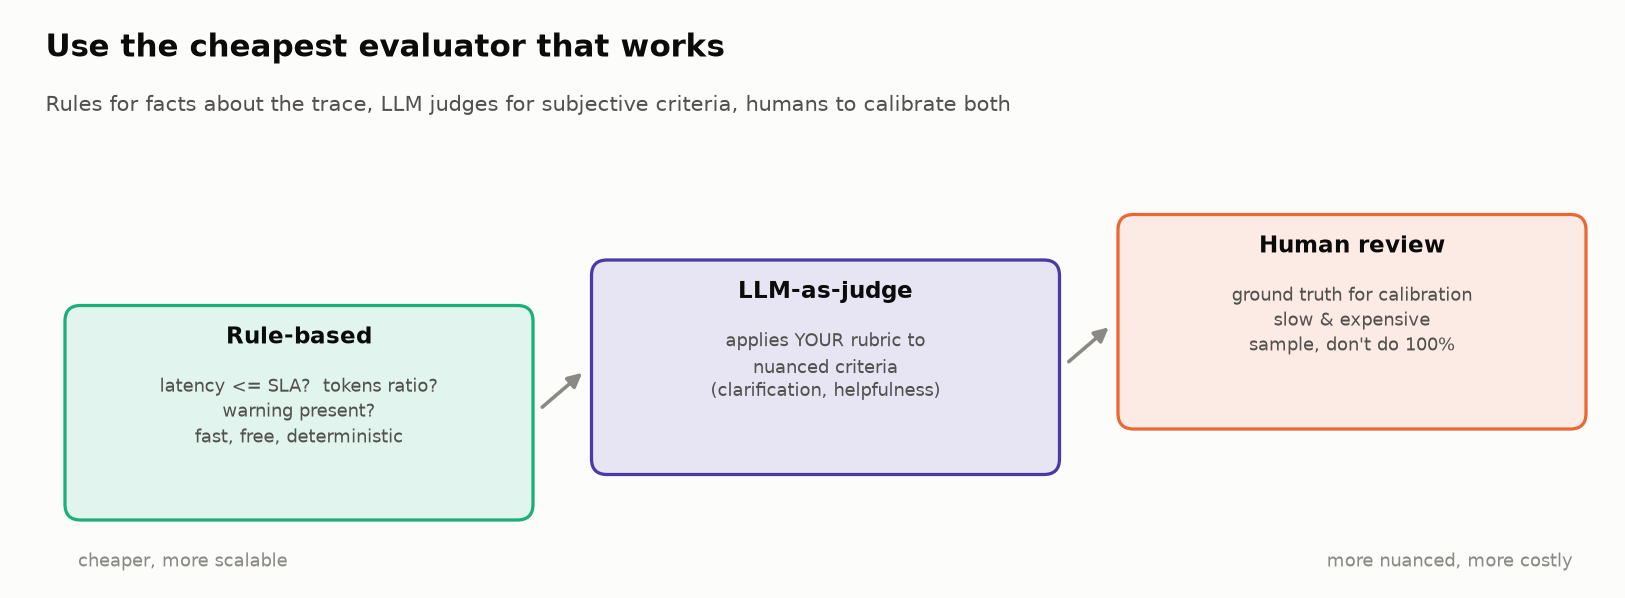

▶️ **Run** (code hidden): keyword patterns for the text rules.

**🎯 Purpose:** Define simple text-pattern helpers.

**🧠 Why this matters:** Cheap deterministic rules are useful baselines precisely because their limitations can be tested. Pattern matching is not semantic understanding.

**🔎 Inspect:** The trailing-question-mark heuristic can pass an unsafe instruction ending in “Anything else?” and miss a valid clarification phrased without a question mark.

In [ ]:
# @title 🧰 Text helpers for the rules: behaviour classifier and keyword patterns (hidden · expand to inspect)
# ============================================================================
# RULE-BASED EVALUATORS
# ============================================================================
DESTRUCTIVE = re.compile(r"\b(delete|remove|erase|wipe|reset)\b", re.I)
WARNING = re.compile(r"\b(irreversible|cannot be undone|permanent|warning)\b", re.I)


def classify_behavior(answer):
    if re.search(r"can only help|outside|not able to help", answer, re.I):
        return "refuse"
    if answer.strip().endswith("?") or re.search(r"do you mean|could you clarify", answer, re.I):
        return "clarify"
    return "answer"

▶️ **Run:** two text rules. Each reads a trace dict `ctx`, returns `(value, comment)` or `None`.

**🎯 Purpose:** Define behavior-match and destructive-warning rules.

**🧠 Why this matters:** These examples teach applicability: a destructive-warning check may be not applicable rather than pass or fail. A warning anywhere does not establish safe ordering.

**🔎 Inspect:** Inspect which fields each rule reads. expected_behavior is an author-supplied fixture label, not a free ground-truth field available for every production request.

In [ ]:
COST_BUDGET_USD = 0.0002     # per request (the 🎛️ experiment below varies it)

# --- Rules that need only the question + answer text --------------------------
def eval_behavior_match(ctx):
    # Did the assistant do what `expected_behavior` says it should?
    observed = classify_behavior(ctx["answer"])
    return int(observed == ctx["expected_behavior"]), f"expected '{ctx['expected_behavior']}', observed '{observed}'"


def eval_destructive_warning(ctx):
    if not DESTRUCTIVE.search(ctx["answer"]):     # only applies when the answer describes a destructive action
        return None
    ok = bool(WARNING.search(ctx["answer"]))
    return int(ok), "warns about irreversibility" if ok else "destructive steps with no warning"

▶️ **Run:** three rules that need the trace: latency, failed steps, cost.

**🎯 Purpose:** Define latency, step-error and known-model-cost checks.

**🧠 Why this matters:** Different rules answer different questions: user wait, operational failure and resource budget. They should not be averaged into a single unexplained quality number.

**🔎 Inspect:** Cost is not scored when a model attempt has unavailable usage. A timed-out attempt is not assumed free, and no-step-errors can fail even when recovery yields a correct answer.

In [ ]:
# --- Rules that need the trace ------------------------------------------------
def eval_latency_sla(ctx):
    return int(ctx["latency"] <= SLA_SECONDS), f"{ctx['latency']:.2f}s vs SLA {SLA_SECONDS}s"


def eval_no_step_errors(ctx):
    errs = ctx["error_steps"]
    return int(not errs), "no failed steps" if not errs else f"failed steps: {errs}"


def eval_cost_budget(ctx):
    if ctx.get("unknown_usage_calls", 0):
        return None  # unavailable usage is not evidence of a free call or a passing budget
    return int(ctx["cost"] <= COST_BUDGET_USD), f"${ctx['cost']:.6f} vs budget ${COST_BUDGET_USD}"


RULE_EVALUATORS = {
    "rule_behavior_match": eval_behavior_match,
    "rule_destructive_warning": eval_destructive_warning,
    "rule_latency_sla": eval_latency_sla,
    "rule_no_step_errors": eval_no_step_errors,
    "rule_cost_budget": eval_cost_budget,
}
TEXT_ONLY_RULES = {"rule_behavior_match", "rule_destructive_warning"}

print(f"Registered {len(RULE_EVALUATORS)} rule evaluators: {list(RULE_EVALUATORS)}")

**🎯 Purpose:** Record a prediction before inspecting the next calculation.

**🧠 Why this matters:** Committing before the reveal makes the evidence easier to interpret and distinguishes what you expected from what the fixture actually shows.

**🔎 Inspect:** This cell stores a choice; a later reveal grades it. The prediction concerns this synthetic sample, not an assumed population rate.

In [ ]:
# @title 🔮 Predict: our deliberately limited text-rule baseline reads all 40 answers, without step data. Of the requests whose TRACE shows a problem, how many did the reviewer also flag?
reviewer_also_flagged = "— pick one —"  # @param ["— pick one —", "A) One or two", "B) About half", "C) Most of them"]

▶️ **Run** (code hidden): `build_context()` (one dict per trace, from the API) and the limited output-only text baseline.

**🎯 Purpose:** Build the scoring context from recorded observations and define the limited text-only baseline.

**🧠 Why this matters:** This mirrors how an evaluation job reconstructs evidence. The baseline is deliberately weak and must not be presented as measured human review.

**🔎 Inspect:** Inspect question, final answer, intent label, error steps, retrieved docs and unknown usage. Observability supplies execution facts; correctness still needs a requirement or reference.

In [ ]:
# @title 🧰 build_context(): one dict per trace, rebuilt from the API, plus the output-only reviewer (hidden · expand to inspect)
# ============================================================================
# BUILD CONTEXT FROM THE API AND RUN EVERY EVALUATOR ON EVERY TRACE
# ============================================================================
# We rebuild everything from the API: exactly what a nightly evaluation job would
# do on yesterday's production traces. One paginated query fetches the whole session.

def build_context(observations):
    t = summarize_trace(observations)
    gens = sorted((o for o in observations if o.type == "GENERATION"), key=lambda o: o.start_time)
    retr = next((o for o in observations if o.type == "RETRIEVER"), None)
    tokens = [token_counts(g.usage_details) for g in gens]
    return {
        "trace_id": t["trace_id"],
        "intent": t["metadata"].get("intent", t["metadata"].get("interaction_type")),
        "question": t["input"],
        "answer": str(t["output"] or as_json(gens[-1].output)),
        "expected_behavior": t["metadata"].get("expected_behavior", "answer"),
        "latency": t["latency"] or 0.0,
        "cost": t["cost"],
        "input_tokens": sum(i for i, _ in tokens), "output_tokens": sum(o for _, o in tokens),
        "llm_calls": len(gens),
        "unknown_usage_calls": sum(not g.usage_details for g in gens),
        "error_steps": [o.name for o in observations if str(o.level) == "ERROR"],
        "retrieved_docs": (as_json(retr.output) or []) if retr else [],
        "retriever_obs_id": retr.id if retr else None,
    }


ADMITS_FAILURE = re.compile(r"\b(sorry|couldn't|could not|unable to|try again)\b", re.I)


def output_only_review(ctx):
    # A weak TEXT HEURISTIC, not a human reviewer and not a full correctness evaluation.
    problems = [n for n in TEXT_ONLY_RULES if (r := RULE_EVALUATORS[n](ctx)) is not None and r[0] == 0]
    if ADMITS_FAILURE.search(ctx["answer"]):
        problems.append("answer admits a failure")
    return problems

▶️ **Run:** every rule on every trace, written back as BOOLEAN scores → read the pass counts.

**🎯 Purpose:** Run every applicable rule and write its score back to the correct trace.

**🧠 Why this matters:** The evaluation loop makes coverage and exclusions explicit. Stable score IDs prevent a rerun from inflating counts for the same evaluation unit.

**🔎 Inspect:** A None is not applicable or unavailable according to the rule contract; it is not a zero or a passing score. The printed denominators count only scored cases.

In [ ]:
# 👀 Look at: every evaluator reads `ctx` (rebuilt from the API, like a nightly job) and writes a BOOLEAN score back to the trace.
obs_by_trace = group_by_trace(get_session_observations(expected=expected_session_obs))
contexts = {tid: build_context(obs_by_trace[tid]) for tid in traffic_ids}

rows, n_scores_written = [], 0
for tid, ctx in contexts.items():
    row = {"trace_id": tid, "intent": ctx["intent"], "latency": ctx["latency"], "cost": ctx["cost"],
           "llm_calls": ctx["llm_calls"], "answer": ctx["answer"]}
    for ev_name, fn in RULE_EVALUATORS.items():
        result = fn(ctx)
        row[ev_name] = None if result is None else result[0]
        if result is not None:
            write_lab_score(trace_id=tid, name=ev_name, value=result[0], data_type="BOOLEAN",
                                  comment=result[1], metadata={"run_id": RUN_ID, "evaluator": "rule"})
            n_scores_written += 1
    row["output_problems"] = output_only_review(ctx)
    row["trace_problems"] = [n for n in RULE_EVALUATORS if n not in TEXT_ONLY_RULES and row[n] == 0]
    rows.append(row)
langfuse.flush()

traffic = pd.DataFrame(rows).set_index("trace_id")
print(f"🎯 {n_scores_written} rule scores written for {len(traffic)} traces.\n")
print(traffic[list(RULE_EVALUATORS)].apply(lambda col: f"{int(col.sum())}/{int(col.notna().sum())} pass").to_string())

▶️ **Run:** what the text baseline flagged vs what the traces showed. Grades your prediction.

**🎯 Purpose:** Compare flags from the text heuristic with flags requiring step data.

**🧠 Why this matters:** This demonstrates complementary evidence rather than proving that text-only evaluation is useless. A proper reference-based answer check could catch errors that this weak baseline misses.

**🔎 Inspect:** Interpret overlap within this synthetic batch. The counts are not a study of human reviewer performance or production failure rates.

In [ ]:
looks_fine = traffic["output_problems"].str.len() == 0
trace_flag = traffic["trace_problems"].str.len() > 0
hidden = traffic[trace_flag & looks_fine]
tiles([
    ("Simulated requests", len(traffic), "controlled fixture", None),
    ("Flagged by text heuristic", int((~looks_fine).sum()), "not measured human performance", "warning"),
    ("Flagged by trace rules", int(trace_flag.sum()), "latency, errors, known cost", "serious"),
    ("Missed by this text heuristic", len(hidden), "among trace-rule flags", "critical"),
])
insight("Compare evaluation methods without overstating what the baseline represents.",
        f"The simple text heuristic flagged {int((~looks_fine).sum())} answers; trace rules flagged {int(trace_flag.sum())} requests. "
        "This does not measure how well a careful human reviewer would perform. A reviewer with current product documentation "
        "could also identify a wrong upload limit from the answer. The trace adds execution evidence: which source was retrieved, "
        "which tool failed, and how long each step took. Combine outcome checks and process checks.")
both = int((trace_flag & ~looks_fine).sum())
_pick = "A" if both <= 0.25 * trace_flag.sum() else "B" if both <= 0.65 * trace_flag.sum() else "C"
quiz("Your prediction: trace problems the reviewer also saw", reviewer_also_flagged, correct=_pick,
     why=f"The heuristic also flagged {both} of {int(trace_flag.sum())} trace-rule failures. This is a comparison within a synthetic fixture, not a human benchmark.")

**Illustration of the injected fault locations.** The original graphic uses “reader” as shorthand for the lab's weak text heuristic. It is not a measurement of human review, and its “invisible” wording means the heuristic lacks step evidence—not that nobody could detect a wrong answer using a trusted reference.

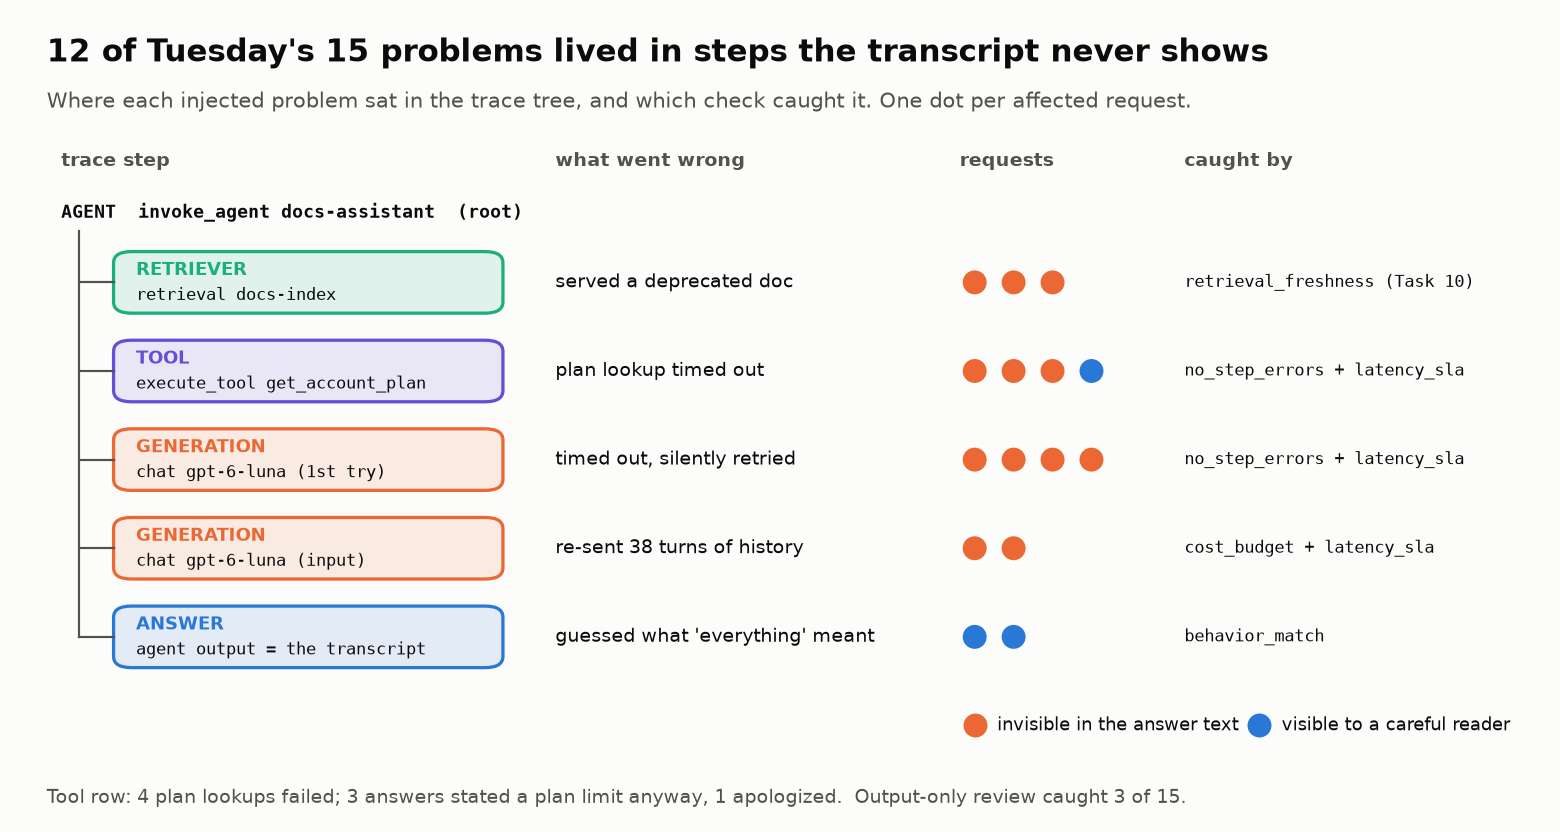

✋ **Your turn:** write a sixth rule, one no reader could apply.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _ref_single_call(ctx):
    return int(ctx["llm_calls"] <= 1)
_ref_calls = [_ref_single_call(c) for c in contexts.values()]

**🎯 Purpose:** Implement a rule on the number of generation attempts.

**🧠 Why this matters:** A retry is invisible in the final answer but visible as another generation observation. The rule operationalizes a measurable process constraint.

**🔎 Inspect:** Count attempts, not just successful outputs. The default exercise is unanswered; later work uses reference results rather than claiming your rule was implemented.

In [ ]:
# ✋ Your turn: a retried LLM call adds another attempt and more waiting; its bill depends on actual usage, and the answer never shows it.
#    ctx["llm_calls"] = how many chat generations the trace holds.
def my_eval_single_call(ctx):
    return ...  # ✏️ 1 if the trace made at most ONE LLM call, else 0

_mine = [my_eval_single_call(c) for c in contexts.values()]
check("A rule only the trace can apply", None if todo(_mine[0]) else _mine, _ref_calls,
      hint="Compare ctx['llm_calls'] with 1, and turn True/False into 1/0 with int(...).",
      success=f"{_ref_calls.count(0)} of {len(_ref_calls)} requests made a second LLM call after a 2 s timeout. Every one read normally.")

🎛️ **Experiment:** drag `COST_BUDGET` across its range. Over what span does the over-budget list stay the same, and what do its requests share? (The rules keep $0.0002.)

**🎯 Purpose:** Explore which requests exceed a chosen known-cost threshold.

**🧠 Why this matters:** A slider makes budget sensitivity visible and prompts inspection of outliers instead of relying only on a mean.

**🔎 Inspect:** This changes the exploratory threshold for the printed list; it does not rewrite earlier recorded budget scores. Unknown failed-call usage can make costs lower bounds.

In [ ]:
COST_BUDGET = 0.0002  # @param {type:"slider", min:0.00005, max:0.0006, step:0.00005}
over = [tid for tid, c in contexts.items() if c["cost"] > COST_BUDGET]
print(f"Budget ${COST_BUDGET:.5f}/request → {len(over)} of {len(contexts)} requests over budget")
for tid in sorted(over, key=lambda t: -contexts[t]["cost"]):
    c = contexts[tid]
    print(f"  ${c['cost']:.6f}  {c['intent']:<9} {c['input_tokens']:>5,} input tokens  {c['output_tokens']:>3} output")

**Checkpoint ✅** Default traffic: **40 requests, 158 scored rule results**, with four cost checks unavailable because the timed-out generations lack usage. Latency passes **30/40**; no-step-errors passes **32/40**. The simple text heuristic flags **3** answers; trace rules flag **10** requests. These are synthetic fixture counts, not human-review performance.

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: rule_latency_sla and rule_no_step_errors often fail on the same traces. Which one points at the cause?
answer = "— pick one —"  # @param ["— pick one —", "A) latency_sla: it measures what the user felt", "B) no_step_errors: it names the step that failed, which is why the request was slow", "C) Neither: causes need an LLM judge", "D) Both equally: they always fail together"]
quiz("Symptom or cause", answer, correct="B",
     why="A timeout burns seconds and then gets retried: the step error comes first and the slow request follows. latency_sla says a user waited; no_step_errors says which step to fix.",
     wrong={"A": "That's the symptom the user feels; the failed step is the cause.",
            "C": "A failed step's name is a trace fact: a rule reads it for free.",
            "D": "Not always: a re-sent history makes a request slow with no step error at all."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Sign off on traces, not transcripts: run cheap trace rules on 100% of traffic.</b></font>

</td></tr></table>

---

## 📊 Task 9: Where Is the Assistant Weakest? (And Why the Mean Lies)

<big><b>The mean is the number on the dashboard; the p95 is the user who churns.</b></big>

> 🎯 **Goal:** pass rates per **slice** with n and an interval; latency as a distribution.<br>
> ❓ **The question:** the mean beats the 1.5 s target. Is it met?<br>
> 👀 **Watch for:** the `account` row; mean vs p95.

> 📘 **Concept · Confidence interval (Wilson)**
>
> **What it is:** the range of true pass rates consistent with *k* passes in *n* tries; the Wilson form stays sensible when *n* is small or *k* is 0.
>
> **What it can't tell you:** whether two slices differ when their intervals overlap. It bounds one rate; it does not compare two.
>
> **Anchor:** a slice that fails 5 of 10 has an interval of 24–76%: wide enough to say *broken*, too wide to prove a fix moved it 10 points.

▶️ **Run:** read the current-version, deduplicated scores back and inspect pass counts by intent and rule. The denominator excludes checks that did not produce a score.

**🎯 Purpose:** Read current-version scores and calculate pass counts by intent slice.

**🧠 Why this matters:** A slice can expose a concentrated failure that an overall average hides. Deduplication protects sample size from repeated writes.

**🔎 Inspect:** Count requests/evaluator results, not raw write events. The Wilson interval below is a sampling illustration; this deliberately constructed fixture is not a random production sample.

In [ ]:
def wilson(k, n, z=1.96):
    # Wilson score interval for a pass rate: honest error bars on small samples.
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


scores = latest_scores([s for s in get_scores(traffic_ids, expected=n_scores_written)
                        if s.name in RULE_EVALUATORS and (s.metadata or {}).get("rubric_version") == RUBRIC_VERSION])
intent_of = {tid: ctx["intent"] for tid, ctx in contexts.items()}
long = pd.DataFrame({"intent": [intent_of[score_trace_id(s)] for s in scores],
                     "rule": [s.name for s in scores], "value": [score_number(s) for s in scores]})

passed = long.pivot_table(index="intent", columns="rule", values="value", aggfunc="sum")
count = long.pivot_table(index="intent", columns="rule", values="value", aggfunc="count")
fail_rate = 1 - passed / count

table = pd.DataFrame(index=fail_rate.index)
for rule in RULE_EVALUATORS:
    if rule in count:
        table[rule.replace("rule_", "")] = [
            "·" if pd.isna(count.loc[i, rule]) else f"{int(passed.loc[i, rule])}/{int(count.loc[i, rule])}"
            for i in table.index]
print(f"Pass counts per slice (read back: {len(scores)} scores)\n")
print(table.to_string())

▶️ **Run** (code hidden): the heatmap and the weakest-slice card.

**🎯 Purpose:** Visualize failures with their sample sizes and a Wilson interval.

**🧠 Why this matters:** A rate without n hides how little evidence supports it. Wide intervals discourage unsupported claims about small improvements.

**🔎 Inspect:** Read failed/n in each cell. The weakest slice is chosen from this dataset; interval interpretation does not remove selection effects or make the fixture representative.

In [ ]:
# @title 📊 Heatmap and the weakest-slice card (hidden · expand to inspect)
# Weakest cell = highest failure rate (ties → larger n)
cells = [(fail_rate.loc[i, r], count.loc[i, r], i, r) for i in fail_rate.index for r in fail_rate.columns
         if not pd.isna(fail_rate.loc[i, r])]
fr, n, w_intent, w_rule = max(cells)
k_fail = int(round(fr * n))
lo, hi = wilson(k_fail, int(n))
overall = 1 - long.loc[long.rule == w_rule, "value"].mean()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols = [r for r in RULE_EVALUATORS if r in fail_rate.columns]
data = fail_rate[cols].values.astype(float)
n_cells = count[cols].values
im = ax.imshow(np.ma.masked_invalid(data), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([c.replace("rule_", "") for c in cols], rotation=20, ha="right")
ax.set_yticks(range(len(fail_rate.index)))
ax.set_yticklabels(fail_rate.index)
ax.grid(False)
for r in range(data.shape[0]):
    for c in range(data.shape[1]):
        n_rc = n_cells[r, c]
        label = "n/a" if np.isnan(n_rc) else f"{int(round(data[r, c] * n_rc))}/{int(n_rc)}"
        ax.text(c, r, label, ha="center", va="center", fontsize=9,
                color="white" if not np.isnan(data[r, c]) and data[r, c] > 0.35 else "#0b0b0b")
ax.set_title(f"'{w_intent}' requests fail {w_rule.replace('rule_', '')} {k_fail}/{int(n)} times (cells: failed/n)")
plt.tight_layout()
plt.show()

insight(
    f"Weakest slice: `{w_intent}` requests fail `{w_rule}` {k_fail}/{int(n)} times ({fr:.0%}, 95% CI {lo:.0%}–{hi:.0%}).",
    f"Morning-wide, that rule fails {overall:.0%} of the time: a tolerable-looking number. The slice view points straight "
    f"at `{w_intent}`. Mind the interval, though: with n = {int(n)} it spans {(hi - lo) * 100:.0f} points, enough to say "
    "*this slice is broken*, not enough to prove a fix moved it 10 points.\n"
    "**Rule of thumb:** report pass rates per slice with n and an interval, and collect more traffic before comparing "
    "two small numbers.",
    kind="warning",
)

<!-- img: slice-intervals.png -->
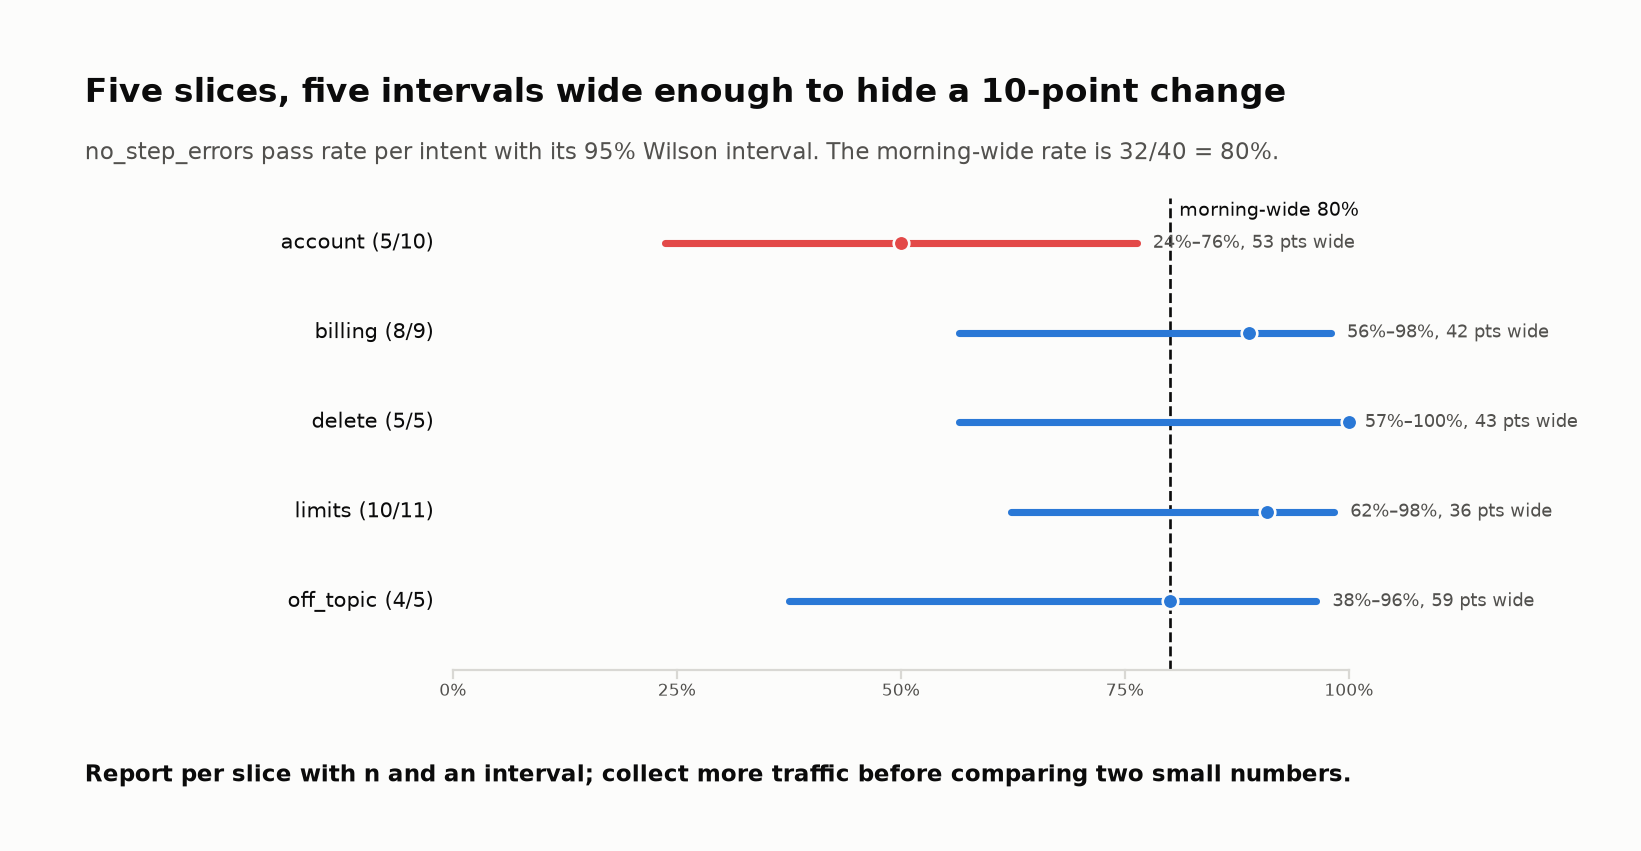
<sub>🖼️ *With 5–11 requests per slice, every interval is wide enough to hide a 10-point change.*</sub>

✋ **Your turn:** how much traffic would it take to prove a fix?

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
def _ci_width(n, fail_rate=0.5):
    lo, hi = wilson(round(fail_rate * n), n)
    return hi - lo
_ref_n = next(n for n in range(10, 1000, 10) if _ci_width(n) < 0.30)

**🎯 Purpose:** Explore how sample size changes an illustrative interval width.

**🧠 Why this matters:** At a fixed observed rate, more independent cases provide more precision. Regrading the same cases does not add independent samples.

**🔎 Inspect:** The reference calculation assumes the stated 50% rate and interval method. It is not a full power analysis or a guarantee of detecting a particular improvement.

In [ ]:
# ✋ Your turn: `account` failed 5 of 10, a 95% interval 53 points wide. At the same 50% rate,
#    how many account requests would you need for an interval under 30 points?
for n in (10, 20):
    lo, hi = wilson(n // 2, n)
    print(f"n = {n:>2}: {lo:.0%}–{hi:.0%}  ({(hi - lo) * 100:.0f} points wide)")

my_n = ...   # ✏️ the smallest multiple of 10 (try wilson(n // 2, n) for a few n)

check("Requests for a 30-point interval", my_n, _ref_n,
      hint="The width shrinks like 1/√n: to cut it by about 1.8×, you need roughly 1.8² ≈ 3–4× the requests.",
      success=f"{_ref_n}: four times Tuesday's account traffic, just to read the rate to ±15 points. Precision costs the square.")

> 📘 **Concept · Percentile (p95)**
>
> **What it is:** the latency that 95% of requests beat: a position in the sorted line-up, not an average.
>
> **What it can't tell you:** how bad the slowest 5% are (that is p99 or the max) or why they are slow; the percentile locates the tail, the trace explains it.
>
> **Anchor:** a mean comfortably under a target can sit next to a p95 nearly twice the target, because the mean averages the slow users away.

**🎯 Purpose:** Record a prediction before inspecting the next calculation.

**🧠 Why this matters:** Committing before the reveal makes the evidence easier to interpret and distinguishes what you expected from what the fixture actually shows.

**🔎 Inspect:** This cell stores a choice; a later reveal grades it. The prediction concerns this synthetic sample, not an assumed population rate.

In [ ]:
# @title 🔮 Predict: mean latency is about 1.2 s, under the 1.5 s SLA. What share of requests breached the SLA?
sla_breach_share_will_be = "— pick one —"  # @param ["— pick one —", "A) Under 5%", "B) About 10%", "C) 25% or more"]

▶️ **Run:** latency and cost as distributions → mean tile vs p95 tile. Grades your prediction.

**🎯 Purpose:** Compute latency quantiles, SLA breaches and concentration of known costs.

**🧠 Why this matters:** Typical behavior, slow-tail behavior and total resource concentration are different views. A favorable mean can coexist with many slow requests.

**🔎 Inspect:** Read the root latency for end-to-end wait. Quantiles depend on sample and interpolation; failed-call usage is not fully measured in this fixture.

In [ ]:
lat = traffic["latency"]
p50, p95, mean = lat.quantile(0.50), lat.quantile(0.95), lat.mean()
slow = traffic[lat > SLA_SECONDS]
slow_explained = int((slow["trace_problems"].apply(lambda ps: "rule_no_step_errors" in ps or "rule_cost_budget" in ps)).sum())
retried = int((traffic["llm_calls"] > 1).sum())

fast_mean, slow_mean = lat[lat <= SLA_SECONDS].mean(), slow["latency"].mean()
breakeven = (SLA_SECONDS - fast_mean) / (slow_mean - fast_mean)   # share of slow requests at which mean = SLA

cost_sorted = traffic["cost"].sort_values(ascending=False)
n_top = max(1, round(0.10 * len(cost_sorted)))
top_share = cost_sorted.head(n_top).sum() / cost_sorted.sum()

tiles([
    ("Mean latency", f"{mean:.2f}s", f"target {SLA_SECONDS}s", "good" if mean <= SLA_SECONDS else "critical"),
    ("p50 latency", f"{p50:.2f}s", "typical user", "good" if p50 <= SLA_SECONDS else "critical"),
    ("p95 latency", f"{p95:.2f}s", "slowest 1 in 20", "good" if p95 <= SLA_SECONDS else "critical"),
    (f"Top {n_top} requests' share of cost", f"{top_share:.0%}", f"{n_top / len(cost_sorted):.0%} of requests", "warning"),
])

_frac = len(slow) / len(lat)
_pick = "A" if _frac < 0.075 else "B" if _frac < 0.2 else "C"
quiz("Your prediction: share of requests over the SLA", sla_breach_share_will_be, correct=_pick,
     why=f"{len(slow)} of {len(lat)} ({_frac:.0%}). The mean blends 30 fast requests and 10 slow ones into a number no request experienced.")

▶️ **Run** (code hidden): the latency histogram and the plot-twist card.

**🎯 Purpose:** Plot the latency distribution with mean, p95 and the target.

**🧠 Why this matters:** A distribution shows which users experience the tail, and a linked trace can explain the relevant steps.

**🔎 Inspect:** Do not infer causation from the histogram alone. Open the slow examples and inspect timeout, tool, or history evidence.

In [ ]:
# @title 📊 Latency histogram and the plot-twist card (hidden · expand to inspect)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
bins = np.arange(0, lat.max() + 0.2, 0.15)
problem = traffic["trace_problems"].str.len() > 0
h_ok = ax.hist(lat[~problem], bins=bins, color=PALETTE[0])[0]
h_bad = ax.hist(lat[problem], bins=bins, color=PALETTE[1])[0]
ymax = max(h_ok.max(), h_bad.max()) * 1.35
ax.set_ylim(0, ymax)
for x, name, color in [(mean, "mean", "#52514e"), (p95, "p95", STATUS["critical"])]:
    ax.axvline(x, color=color, lw=1.6, ls="--")
    ax.text(x + 0.03, ymax * 0.93, f"{name} {x:.2f}s", color=color, fontsize=10)
ax.axvspan(SLA_SECONDS, lat.max() + 0.2, color=STATUS["critical"], alpha=0.06)
ax.text(SLA_SECONDS + 0.03, ymax * 0.80, f"over the {SLA_SECONDS}s SLA", color="#52514e", fontsize=9)
# direct labels instead of a legend
ax.text(lat[~problem].median(), h_ok.max() + ymax * 0.03, "no trace problem", color=PALETTE[0], ha="center", fontsize=10)
ax.text(lat[problem].median(), h_bad.max() + ymax * 0.03, "failed step / over budget", color=PALETTE[1], ha="center", fontsize=10)
ax.set_xlabel("request latency (s)")
ax.set_ylabel("requests")
ax.set_title(f"The mean says 'within SLA'. The p95 is {p95 / SLA_SECONDS:.1f}× over it.")
plt.tight_layout()
plt.show()

insight(
    f"Plot twist: mean latency {mean:.2f}s passes the {SLA_SECONDS}s target, but p95 is {p95:.2f}s.",
    f"The slowest 1 in 20 users wait {p95 / p50:.1f}× the typical user's {p50:.2f}s. {len(slow)} of {len(lat)} requests "
    f"({len(slow) / len(lat):.0%}) broke the SLA; "
    f"{slow_explained} of them have the cause written in the trace: a retried timeout ({retried} requests made 2 LLM calls), "
    f"a timed-out tool, or 38 turns of re-sent history. At these fast/slow averages the mean would stay under "
    f"{SLA_SECONDS}s until about {breakeven:.0%} of requests were slow. Cost has the same shape: the top {n_top} requests used "
    f"{top_share:.0%} of the morning's spend. The mean averages away exactly the users who churn and the requests that "
    "blow the budget.\n"
    "**Rule of thumb:** set latency targets on p95/p99 and report cost per request as a distribution.",
    kind="surprise",
)

<!-- img: comic-average-user.png -->
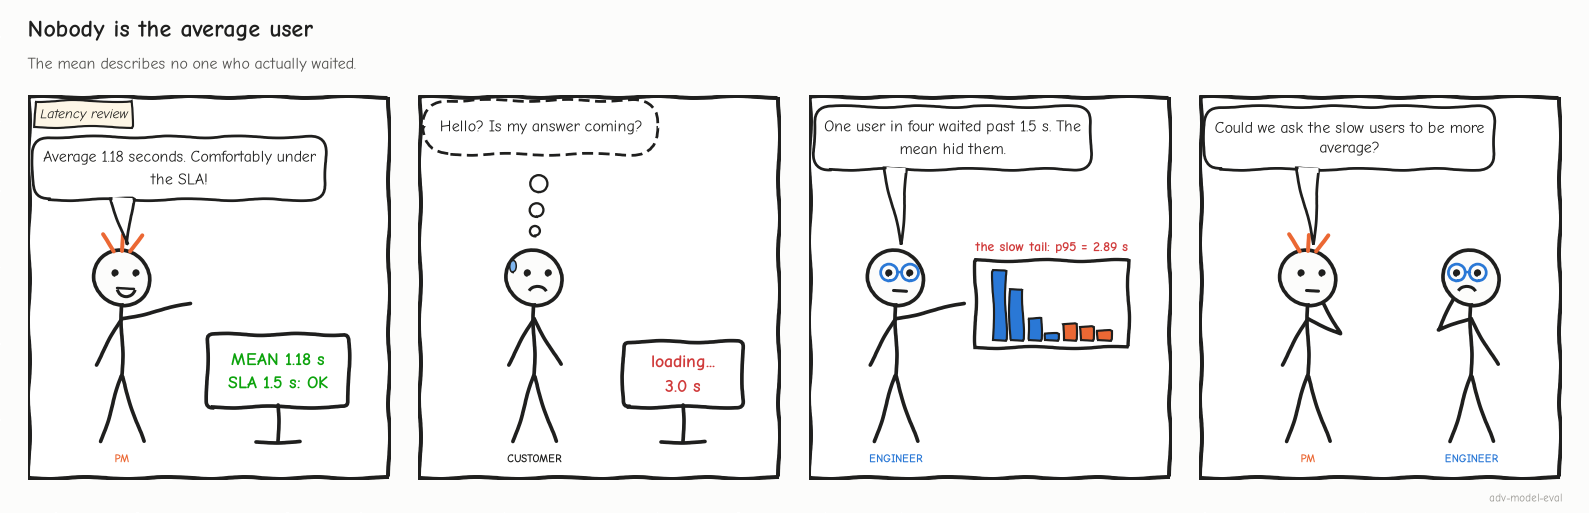
<sub>🖼️ *Nobody is the average user.*</sub>

🔍 **What just happened:** latency has a floor but no ceiling (**right-skewed**). The mean of two groups is (1 − f) × fast + f × slow, so it stays green long after many users are hurt.

🗣️ **Say it to a colleague:** "Set the target on the p95 and put the reason for the slow 5% in the trace. The mean is the one number that never pages."

<!-- img: mean-vs-tail.png -->
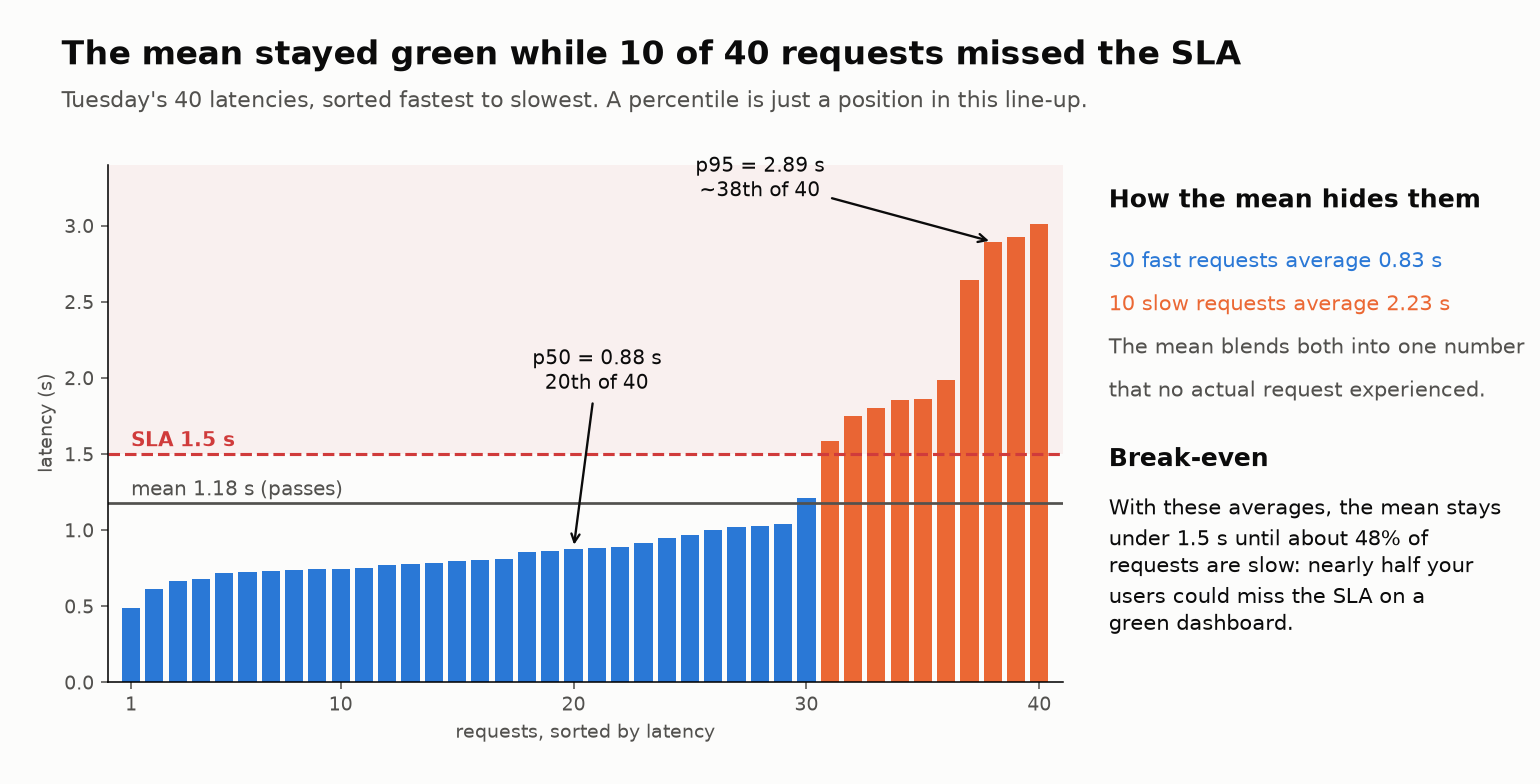
<sub>🖼️ *A percentile is a position in the sorted line-up. The mean is not a position at all.*</sub>

🎛️ **Experiment:** drag `SLOW_SHARE` until the mean crosses 1.5 s. Tuesday was at 25%.

**🎯 Purpose:** Turn observed latency evidence into a release discussion.

**🧠 Why this matters:** Metrics report measurements; a policy decides what failures block release. Performance thresholds should reflect a product requirement.

**🔎 Inspect:** Use the displayed values rather than static prose if you change seeds, timings or thresholds. State whether the requirement concerns every request or a percentile.

In [ ]:
SLOW_SHARE = 0.25  # @param {type:"slider", min:0, max:0.8, step:0.05}
mix_mean = (1 - SLOW_SHARE) * fast_mean + SLOW_SHARE * slow_mean    # fast and slow averages from Tuesday
print(f"{SLOW_SHARE:.0%} of requests slow → mean {mix_mean:.2f}s: "
      f"{'✅ looks within' if mix_mean <= SLA_SECONDS else '⛔ finally over'} the {SLA_SECONDS}s SLA, "
      f"while {SLOW_SHARE:.0%} of users waited past it.  (fast avg {fast_mean:.2f}s · slow avg {slow_mean:.2f}s)")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Weakest cell `account × no_step_errors` **5/10 (CI 24%–76%)**; tiles **mean 1.18 s ✅ · p50 0.88 s ✅ · p95 2.89 s ⛔ · top 4 requests = 45% of cost**; the mean turns red near 50% slow. In the Langfuse UI, filter *Traces* by `rule_no_step_errors = false`.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: after a fix, account fails no_step_errors 3 of 10 times instead of 5 of 10. Can you claim the fix worked?
answer = "— pick one —"  # @param ["— pick one —", "A) Yes: failures fell from 50% to 30%", "B) Yes, if the overall rate fell too", "C) No: the fix made no difference", "D) Not yet: at n = 10 the two intervals overlap almost entirely"]
_lo, _hi = wilson(3, 10)
quiz("Did the fix work?", answer, correct="D",
     why=f"3 of 10 has a 95% interval of {_lo:.0%}–{_hi:.0%}; 5 of 10 had 24%–76%. Collect more traffic (your ✋ answer above) before you claim a 20-point move.",
     wrong={"A": "That's the point estimate; with n = 10 it moves that much by chance.",
            "B": "The overall rate mixes in four other slices; it can't vouch for this one.",
            "C": "That's just as unproven: the data can't tell either way yet."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Report pass rates per slice with n and an interval, and latency as p95, never the mean.</b></font>

</td></tr></table>

---

## 🕵️ Task 10: Root-Cause a Wrong Answer That Passed Every Rule

<big><b>A fluent wrong answer about an upload limit is a wrong tax rate in another product.</b></big>

> 🎯 **Goal:** trace a wrong answer to *the step* that caused it; score that step.<br>
> ❓ **The question:** two clean answers disagree. Which step lied?<br>
> 👀 **Watch for:** the retriever's `status` and `version` fields.

▶️ **Run:** the upload-limit answers that passed every rule.

**🎯 Purpose:** Inspect answers that passed the initial rules.

**🧠 Why this matters:** Passing a suite only shows that the suite did not detect a failure. It does not establish correctness of untested claims.

**🔎 Inspect:** Two different upload limits appear among superficially clean answers. Bring the current documented requirement before deciding which answer is wrong.

In [ ]:
rule_cols = list(RULE_EVALUATORS)
all_pass = traffic[rule_cols].fillna(1).eq(1).all(axis=1)
clean_limits = traffic[all_pass & (traffic["intent"] == "limits")]

print(f"{int(all_pass.sum())} of {len(traffic)} requests passed every rule.")
print(f"Of those, {len(clean_limits)} were questions about upload limits. Their answers:\n")
for answer, n in Counter(clean_limits["answer"]).most_common():
    print(f"  {n:>2} ×  \"{answer}\"")

> 📘 **Concept · First upstream failure**
>
> **What it is:** the earliest observation in a trace that departed from correct behaviour; every step after it inherits the error.
>
> **What it can't tell you:** it needs the trace tree. The final answer shows where the user *saw* the failure, not where it started.
>
> **Anchor:** two fluent answers to the same question disagree; the model step is faithful in both, so the cause sits further up.

**🎯 Purpose:** Record a prediction before inspecting the next calculation.

**🧠 Why this matters:** Committing before the reveal makes the evidence easier to interpret and distinguishes what you expected from what the fixture actually shows.

**🔎 Inspect:** This cell stores a choice; a later reveal grades it. The prediction concerns this synthetic sample, not an assumed population rate.

In [ ]:
# @title 🔮 Predict: two clean answers to the same question disagree (500 MB vs 100 MB). Which step do you suspect first?
first_failure_will_be = "— pick one —"  # @param ["— pick one —", "A) The model invented a number", "B) The retriever handed over a wrong document", "C) The question was ambiguous"]

▶️ **Run:** the same question twice: the healthy index vs Tuesday's.

**🎯 Purpose:** Create a controlled good/bad pair differing in retrieved document version.

**🧠 Why this matters:** Holding the question and scenario fixed narrows the investigation to the upstream information supplied to the answer step.

**🔎 Inspect:** The simulator produces canned answers from those selections. Follow the trace to verify the causal mechanism built into this controlled example.

In [ ]:
QUESTION = "What's the per-file upload limit on the enterprise plan?"
rag_traces = {}
for variant, stale in [("healthy", False), ("buggy", True)]:
    tid = run_assistant(QUESTION, "limits", random.Random(1), stale_index=stale, tags=("rag-demo", variant))
    rag_traces[variant] = tid
    trace_ids[f"rag_{variant}"] = tid
langfuse.flush()

for variant, tid in rag_traces.items():
    t = get_trace(tid, expected=3)
    print(f"✅ {variant:<8} → {t['output']}")
    print(f"   🔗 {trace_link(tid)}")

▶️ **Run:** the buggy trace, step by step → read the retriever's documents. Grades your prediction.

**🎯 Purpose:** Inspect the stale retrieval and generation context.

**🧠 Why this matters:** Root-cause analysis follows the wrong fact upstream instead of treating the model as the only possible failure source.

**🔎 Inspect:** Compare document IDs, version and status. Similarity is synthetic here and is not evidence that a source is current or true.

In [ ]:
buggy_obs = get_observations(rag_traces["buggy"], expected=3)
print_tree(buggy_obs)

retr = next(o for o in buggy_obs if o.type == "RETRIEVER")
print("\n📄 What the retriever handed to the LLM:")
for d in as_json(retr.output) or []:
    print(f"   {d['id']:<15} v={d['version']}  status={d['status']:<10} sim={d['similarity']}  “{d['text']}”")

_stale = any(d["status"] != "current" for d in as_json(retr.output) or [])
quiz("Your prediction: the first step that went wrong", first_failure_will_be, correct="B" if _stale else "A",
     why="The retriever ranked a deprecated v1 document first; the model answered faithfully from it. Errors compound downstream: fix the first upstream failure (Husain & Shankar, *AI Evals FAQ*, 2026).")

### 🖥️ Langfuse investigation 4 · follow the wrong number upstream

Open the `buggy` link printed below. Select the retriever and read each returned document's **ID, version, status, text, and synthetic similarity**. Then select the generation and find the outdated limit in its context. Finally inspect the answer.

**Explain the distinction:** the answer is faithful to the supplied source but incorrect against current product documentation. Freshness checks help prevent this particular failure; they do not establish relevance, authorization, completeness, or truth of every claim. Historical questions may legitimately require older documents, so “current only” is a policy for this lab's present-day upload questions, not a universal retrieval rule.

After the next scoring cell, return to the **retriever node's Scores**. Confirm `retrieval_freshness` is attached to that step, while `correctness` describes the overall answer.

**🎯 Purpose:** Print links to the specific observations named in the UI investigation.

**🧠 Why this matters:** A focused example connects the question in the checklist to inspectable recorded evidence.

**🔎 Inspect:** Follow the links in Langfuse mode, or inspect local trees. Read both the failed operation and the final answer before making a diagnosis.

In [ ]:
for name, tid in rag_traces.items():
    print(name, trace_link(tid))

✋ **Your turn:** score the *step*, not the trace. Write a check on the retriever's output that needs no reference answer.

**🎯 Purpose:** Define a freshness check with explicit empty/missing-evidence behavior.

**🧠 Why this matters:** A rule that uses all() alone accidentally passes an empty list. Absence of retrieval evidence must not masquerade as verified freshness.

**🔎 Inspect:** The reference requires at least one document and every status marked current. It is a present-day-source policy, not a general truth or relevance check.

In [ ]:
# @title 🧰 Reference freshness evaluator (expand only after trying your implementation)
def _freshness(docs):
    if not isinstance(docs, list) or not docs:
        return 0, "no documents: freshness is not established"
    stale = [d.get("id", "unknown") if isinstance(d, dict) else "malformed" for d in docs
             if not isinstance(d, dict) or d.get("status") != "current"]
    return (0 if stale else 1), (f"not confirmed current: {stale}" if stale else "all documents marked current")
_all_docs = [c["retrieved_docs"] for c in contexts.values()] + [[]]

**🎯 Purpose:** Implement and test your own retrieval freshness check.

**🧠 Why this matters:** The exercise turns an investigation into a repeatable step-level evaluator and includes an empty retrieval to expose a common blind spot.

**🔎 Inspect:** Return 0 for empty evidence and deprecated sources. A successful freshness score does not prove that the answer used all necessary facts correctly.

In [ ]:
# ✋ Your turn: each retrieved doc is a dict with id, text, version, status ("current" | "deprecated"), similarity.
def my_freshness(retrieved_docs):
    return ...  # ✏️ 1 if there is at least one document AND every status is "current"; else 0

_mine = [my_freshness(d) for d in _all_docs]
check("Retrieval freshness: a reference-free step check", None if todo(_mine[0]) else _mine,
      [_freshness(d)[0] for d in _all_docs],
      hint="Require a nonempty list as well as all statuses being current. all([]) is True, which would otherwise hide an empty retrieval.",
      success=f"{sum(1 - _freshness(d)[0] for d in _all_docs)} of {len(_all_docs)} test inputs fail freshness (the suite includes an empty retrieval). "
              "No reference answer needed: the check reads the step, so it can run on 100% of traffic.")

▶️ **Run:** scores `retrieval_freshness` on the **retriever observation** (`observation_id=`) for both demo traces.

**🎯 Purpose:** Attach freshness to the retriever and correctness to the answer trace.

**🧠 Why this matters:** The target of a score is part of its meaning. Step scores help identify where to investigate, while outcome scores describe the user-facing result.

**🔎 Inspect:** Open the retriever node in Langfuse to find freshness. The narrow correctness reference is the current Enterprise limit, 500 MB.

In [ ]:
# 👀 Look at: observation_id= attaches the score to the RETRIEVER node, not to the whole trace.
for variant, tid in rag_traces.items():
    ctx = build_context(get_observations(tid, expected=3))
    value, comment = _freshness(ctx["retrieved_docs"])
    write_lab_score(trace_id=tid, observation_id=ctx["retriever_obs_id"], name="retrieval_freshness",
                          value=value, data_type="BOOLEAN", comment=comment, metadata={"run_id": RUN_ID})
    correct = int("500 MB" in ctx["answer"])            # ground truth from the current docs
    write_lab_score(trace_id=tid, name="correctness", value=float(correct),
                          comment="Compared against current docs (500 MB).", metadata={"run_id": RUN_ID})
    print(f"{variant:<8} retrieval_freshness={value}  correctness={correct}   ({comment})")

▶️ **Run** (code hidden): scores the whole morning, reference-free, and two cards.

**🎯 Purpose:** Apply freshness checks to the simulated morning.

**🧠 Why this matters:** A reusable evaluator can find the same class of failure across more cases without needing a reference answer for every question.

**🔎 Inspect:** This fixture makes deprecated limits produce wrong answers; in general a stale-document flag is a process concern, not proof that every resulting answer is wrong.

In [ ]:
# @title 📊 Score the whole morning, reference-free, and the two cards (hidden · expand to inspect)
# 2) the whole morning: no reference answer needed
traffic["retrieval_freshness"] = 0
for tid, ctx in contexts.items():
    value, comment = _freshness(ctx["retrieved_docs"])
    traffic.loc[tid, "retrieval_freshness"] = value
    write_lab_score(trace_id=tid, observation_id=ctx["retriever_obs_id"], name="retrieval_freshness",
                          value=value, data_type="BOOLEAN", comment=comment, metadata={"run_id": RUN_ID})
langfuse.flush()

stale_ids = traffic.index[traffic["retrieval_freshness"] == 0]
stale_and_clean = int(all_pass[stale_ids].sum())
print(f"\nretrieval_freshness on the morning's traffic: {len(stale_ids)} of {len(traffic)} requests used a deprecated document.")

insight(
    f"`retrieval_freshness` flagged {len(stale_ids)} requests with deprecated context, and {stale_and_clean} of them had passed every other rule.",
    "The buggy answer was fluent and *faithful*: the LLM used exactly the context it was given. It was wrong because the "
    "retriever served a deprecated document. An answer-only check cannot reveal which document was retrieved. A correctness check may still detect the wrong number when it has a trusted reference "
    "answer you rarely have in production. A check on the **step** (is every retrieved document current?) needs no "
    "reference, so it can run on every request.\n"
    "**Rule of thumb:** faithful ≠ correct; score the step, reference-free, and attach the score to the observation that "
    "failed (`observation_id`) so the alert says *where*.",
)
insight(
    "Swap '100 MB' for last year's standard deduction or a superseded sales-tax rate.",
    "In a tax or accounting assistant the same bug yields a confident, well-written, *wrong number*, faithful to its "
    "source; there, a wrong number can lead to serious downstream decisions. Regulatory indexes go stale on a calendar (new "
    "tax year, new rate tables): give documents `effective_from`/`status` metadata, filter on it at retrieval time, score "
    "freshness on every trace, and route answers that cite superseded documents to a human expert.",
    kind="production",
)

<!-- img: rag-root-cause.png -->
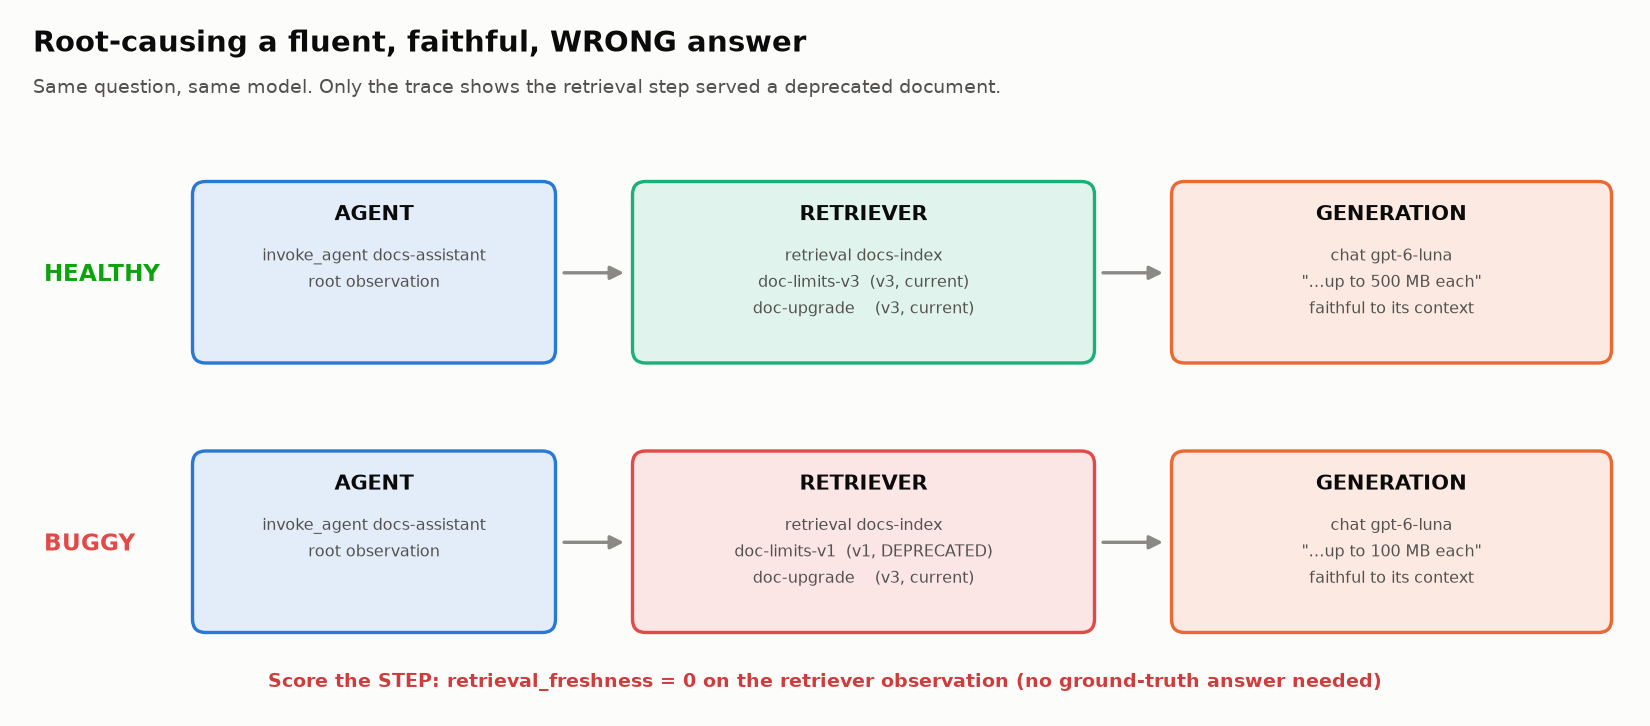
<sub>🖼️ *The answer was fluent AND faithful, yet wrong; only the retriever observation shows why*</sub>

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Clean answers in two versions (7 × 500 MB, 3 × 100 MB); the buggy retriever lists `doc-limits-v1 … status=deprecated`; `buggy retrieval_freshness=0 correctness=0`; `3 of 40 requests used a deprecated document`.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: the model wrote 100 MB because the document it was given said 100 MB. Which property did the answer fail?
answer = "— pick one —"  # @param ["— pick one —", "A) Correctness only: it was faithful to a stale document", "B) Faithfulness: it made the number up", "C) Both faithfulness and correctness", "D) Neither: it quoted its source"]
quiz("Faithful vs correct", answer, correct="A",
     why="Faithful means it sticks to its context; correct means it is true. A stale document produces faithful-but-wrong, which a faithfulness judge passes and a step check on the retriever catches.",
     wrong={"B": "The number is in the retrieved v1 document; the model copied it.",
            "C": "It stuck to its context exactly: that's faithful.",
            "D": "Quoting a deprecated source still tells the user something false."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Faithful is not correct: score the step that first went wrong, reference-free, on every request.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 3 of 3 (Tasks 11–12): automate judgment, check it, then sign.

## ⚖️ Task 11: LLM-as-Judge (real judge optional: needs an OpenAI key)

<big><b>An uncalibrated judge is a second opinion from someone you have never checked.</b></big>

> 🎯 **Goal:** run an **LLM judge**, compare it with your labels, price it.<br>
> ❓ **The question:** would you run this judge on every request?<br>
> 👀 **Watch for:** scores where the rubric doesn't apply.

The mock is a <mark>deliberately naive judge: it only checks for a trailing "?"</mark>. `PROVIDER = "openai"` + a key runs `JUDGE_MODEL` with **structured output**.

▶️ **Run:** the verdict schema and the judge prompt.

**🎯 Purpose:** Define the structured judge verdict and evaluation prompt.

**🧠 Why this matters:** A judge needs an explicit rubric, scale, input and answer. Structured output constrains the return shape but does not make the judgment correct.

**🔎 Inspect:** None means not applicable only when the judge successfully returns that judgment. Provider refusals or parsing failures must be tracked as evaluator errors.

In [ ]:
from typing import Optional
from pydantic import BaseModel


class JudgeVerdict(BaseModel):
    reasoning: str
    score: Optional[float]      # None = the criterion does not apply to this answer


JUDGE_INSTRUCTIONS = ("You evaluate a product-documentation Q&A assistant against one criterion. "
                      "Apply the rubric literally. If the criterion does not apply, return score = null.")
JUDGE_PROMPT = '''Criterion: {name}
Question to answer: {description}
Rubric: {rubric}
Scale: {scale}  (binary → 0 or 1; 1-5 → integer 1..5)

User question:
{question}

Assistant answer:
{answer}'''

▶️ **Run** (code hidden): mock judge, OpenAI client, traced `evaluator` step.

**🎯 Purpose:** Prepare the intentionally weak mock judge or the optional real Responses API client.

**🧠 Why this matters:** The mock exposes known failure modes without cost. A real judge needs a key and produces uncertain judgments that still need calibration.

**🔎 Inspect:** Only the real-judge branch makes model calls. Its numeric scale is validated; failed execution is not recorded as a passing application score.

In [ ]:
# @title 🧰 Judge plumbing: mock judge, OpenAI Responses client, traced evaluator observation (hidden · expand to inspect)
def _make_judge_client():
    if PROVIDER != "openai":
        return None
    key = _load_secret("OPENAI_API_KEY")
    if not key:
        print("⚠️  PROVIDER='openai' but no OPENAI_API_KEY was found: using the mock judge.")
        return None
    if MODE == "langfuse":
        from langfuse.openai import OpenAI   # drop-in: every responses.create/parse call becomes a traced generation
    else:
        from openai import OpenAI
    return OpenAI(api_key=key)


judge_client = _make_judge_client()
print(f"🤖 Judge: {JUDGE_MODEL} (real, Responses API)" if judge_client else
      "🎭 Judge: mock (checks only whether the answer ends with '?'). Not a real evaluator!")


def mock_judge(criterion, question, answer):
    asks = answer.strip().endswith("?")
    guess = (4 if asks else 2) if criterion["scale"] == "1-5" else (1 if asks else 0)
    return {"reasoning": "mock judge: looks only at whether the answer ends with a question mark.", "score": guess}


def _call_judge(criterion, prompt, question, answer):
    if judge_client is None:
        verdict = mock_judge(criterion, question, answer)
        return verdict, (len(JUDGE_INSTRUCTIONS + prompt) // 4, len(json.dumps(verdict)) // 4)   # ≈ 4 chars/token
    resp = judge_client.responses.parse(model=JUDGE_MODEL, instructions=JUDGE_INSTRUCTIONS,
                                        input=prompt, text_format=JudgeVerdict)
    parsed = resp.output_parsed
    verdict = parsed.model_dump() if parsed else {"reasoning": "no parsed output (refusal or error)", "score": None, "status": "error"}
    if verdict["score"] is not None:
        value = verdict["score"]
        allowed = (value in (0, 1) if criterion["scale"] == "binary" else
                   math.isfinite(value) and value == int(value) and 1 <= value <= 5)
        if not allowed:
            raise ValueError("Judge returned a score outside the criterion scale")
    return verdict, (resp.usage.input_tokens, resp.usage.output_tokens)


def judge(criterion, question, answer, evaluated_trace_id):
    # Run the judge inside its own 'evaluator' observation so the judge itself is traced.
    prompt = JUDGE_PROMPT.format(question=question, answer=answer, **criterion)
    with propagate_attributes(trace_name=f"judge-{criterion['name']}", session_id=RUN_ID,
                              tags=["module-01-lab", "judge"]):
        with langfuse.start_as_current_observation(
            as_type="evaluator", name=f"judge-{criterion['name']}",
            input={"criterion": criterion["name"], "evaluated_trace_id": evaluated_trace_id},
        ) as ev:
            if judge_client is not None and MODE == "langfuse":
                verdict, usage = _call_judge(criterion, prompt, question, answer)   # auto-traced by the wrapper
            else:
                with langfuse.start_as_current_observation(
                    as_type="generation", name=f"chat {JUDGE_MODEL}", model=JUDGE_MODEL,
                    input=[{"role": "system", "content": JUDGE_INSTRUCTIONS}, {"role": "user", "content": prompt}],
                    metadata={"simulated": judge_client is None},
                ) as gen:
                    if judge_client is None:
                        simulate_latency(0.4)
                    verdict, usage = _call_judge(criterion, prompt, question, answer)
                    gen.update(output=verdict, usage_details={"input": usage[0], "output": usage[1]},
                               cost_details=cost_usd(JUDGE_MODEL, *usage))
            ev.update(output=verdict)
            return verdict, usage


print("✅ Judge ready")

▶️ **Run:** the judge on three Part 1 traces → one ⚖️ line each.

**🎯 Purpose:** Run supported numeric judge criteria and attach successful judgments.

**🧠 Why this matters:** Judging and storing a result are separate operations. The loop reports execution failures and skips N/A results instead of silently treating them as quality passes.

**🔎 Inspect:** Binary and 1–5 criteria are supported here. Categorical criteria require a different output schema. The printed OTel event is illustrative, not a second exported evaluation.

In [ ]:
# Judges every llm_judge criterion in my_evaluation_criteria (the catch-up cell holds Part 1's worked example).
judge_criteria = [c for c in my_evaluation_criteria
                  if c.get("method") == "llm_judge" and c.get("scale") in {"binary", "1-5"} and "TODO" not in c.values()]
print("This numeric judge runner handles binary and 1–5 criteria. Categorical criteria need a category schema and are not sent to it.")
targets = ["ambiguous_question", "simple_factual", "out_of_scope"]

judge_results, judge_usage, judge_errors = {}, [], []
for c in judge_criteria:
    for trace_name in targets:
        tid = trace_ids[trace_name]
        ctx = build_context(get_observations(tid, expected=2))
        try:
            jv, usage = judge(c, ctx["question"], ctx["answer"], tid)
            if jv.get("status") == "error":
                raise ValueError(jv["reasoning"])
        except Exception as exc:
            judge_errors.append((trace_name, c["name"], type(exc).__name__))
            print(f"EVALUATOR ERROR on {trace_name}: {type(exc).__name__}. Inspect the evaluator trace; no quality score was written.")
            continue
        judge_usage.append(usage)
        if jv["score"] is None:
            print(f"⚖️  {c['name']:<22} on {trace_name:<20} → n/a (not scored)")
            continue
        value = float(jv["score"])
        judge_results[(trace_name, c["name"])] = value
        write_lab_score(
            trace_id=tid, name=f"judge_{c['name']}", value=value, comment=jv.get("reasoning", ""),
            metadata={"run_id": RUN_ID, "evaluator": "llm_judge",
                      "judge_model": JUDGE_MODEL if judge_client else "mock"},
        )
        print(f"⚖️  {c['name']:<22} on {trace_name:<20} → {value:g}   {jv.get('reasoning', '')[:70]}")
langfuse.flush()

# The same judgment, expressed as the (experimental) OTel GenAI evaluation event.
# Only gen_ai.evaluation.name is required; the score/explanation keys below follow the draft and may change.
if judge_results:
    first_key = next(iter(judge_results))
    print("\nOTel view of the first judgment:")
    print(json.dumps({"event.name": "gen_ai.evaluation.result",
                      "gen_ai.evaluation.name": f"judge_{first_key[1]}",
                      "gen_ai.evaluation.score.value": judge_results[first_key],
                      "gen_ai.evaluation.explanation": "see the score comment"}, indent=2))

> 📘 **Concept · Judge calibration**
>
> **What it is:** comparing a judge's scores with human scores on the same items before trusting it: agreement per item, not a feeling.
>
> **What it can't tell you:** much, when the items are all easy; agreement on easy cases is cheap. Count the hard cases (and, from Lab 05 on, TPR and TNR).
>
> **Anchor:** the mock judge agrees with you exactly where *ends with a question mark* happens to be the right rule, and nowhere else.

✋ **Your turn:** calibrate the judge against yourself. Label the three answers before you compare.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_labels = [0, None, None]   # ambiguous: didn't ask · the other two aren't ambiguous: doesn't apply

**🎯 Purpose:** Apply the clarification rubric yourself before comparing with the judge.

**🧠 Why this matters:** Human/reference labels need applicability as well as a number. Grading a non-ambiguous request on clarification creates misleading disagreements.

**🔎 Inspect:** Use the exact target order. Your submitted valid labels drive the next comparison; unanswered or malformed labels are explicitly replaced by the reference fixture.

In [ ]:
# ✋ Your turn: apply the intent_clarification rubric yourself. 1 = asks first; 0 = assumes; None = doesn't apply.
_qa = {it["name"]: it for it in QA_INTERACTIONS}
for name in targets:
    print(f"{name}\n  Q: {_qa[name]['user']}\n  A: {_qa[name]['assistant']}")

my_labels = ...   # ✏️ a list of three (0, 1 or None), in the order printed

check("Your labels for intent_clarification", my_labels, _ref_labels,
      hint="The rubric starts 'When the request is ambiguous…'. Is a question about upload size, or the weather, ambiguous?",
      success="0, None, None: only 'delete everything' is ambiguous. The deliberately naive mock judge scores all three (a real judge may correctly abstain), "
              "so two of its verdicts grade cases the rubric doesn't cover. Most early disagreements are rubric problems.")

▶️ **Run:** you vs the judge, pair by pair (reference labels).

**🎯 Purpose:** Compare your valid submitted labels with matching judge results.

**🧠 Why this matters:** A calibration comparison must use the labels the learner actually supplied and exclude N/A items from numeric agreement.

**🔎 Inspect:** Read the printed label source. One applicable item cannot establish judge reliability; Studio C adds both positive and negative cases plus a coverage report.

In [ ]:
valid_labels = (isinstance(my_labels, list) and len(my_labels) == len(targets)
                and all(x is None or type(x) is int and x in (0, 1) for x in my_labels))
labels_used = my_labels if valid_labels else _ref_labels
label_source = "your submitted labels" if valid_labels else "REFERENCE labels (student labels unanswered or invalid)"
print("Comparison uses:", label_source)
my_manual_scores = {(name, "intent_clarification"): label for name, label in zip(targets, labels_used)}
pairs = [(k, h, judge_results[k]) for k, h in my_manual_scores.items() if h is not None and k in judge_results]
na_scored = [k for k, h in my_manual_scores.items() if h is None and k in judge_results]

agree = sum(1 for _, h, j in pairs if abs(h - j) < 0.5)
for (trace_name, crit), h, j in pairs:
    print(f"  {'✅' if abs(h - j) < 0.5 else '❌'} {crit:<22} {trace_name:<20} you={h:g}  judge={j:g}")
for trace_name, crit in na_scored:
    print(f"  ⚠️  {crit:<22} {trace_name:<20} you=n/a  judge={judge_results[(trace_name, crit)]:g}  (judge scored a case that doesn't apply)")
if pairs:
    insight(
        f"Using {label_source}, agreement with the judge is {agree} of {len(pairs)} judgments ({agree / len(pairs):.0%}); "
        f"the judge also scored {len(na_scored)} case(s) you marked as not applicable.",
        "Read each disagreement's `reasoning` (the score comment) before blaming the judge: on a new rubric most "
        "disagreements are rubric problems, such as a criterion that is undefined when there is nothing to clarify.\n"
        "**Rule of thumb:** fix the rubric first, then measure the judge on a labelled set with both passes and fails, "
        "reporting true-positive and true-negative rates separately (Module 05 adds Cohen's κ).",
    )

▶️ **Run:** the price of judging every request → last two tiles.

**🎯 Purpose:** Estimate judge cost from successful calls and compare this fixture’s chosen configurations.

**🧠 Why this matters:** Evaluation itself consumes resources, but the ratio depends on models, rubric length, answer length and coverage. Mock estimates are not a production budget.

**🔎 Inspect:** The 2% tile estimates the random sample only; flagged cases cost extra. If all real calls fail, the report withholds the projection rather than treating missing usage as zero cost.

In [ ]:
REQUESTS_PER_MONTH = 1_000_000
app_cost = traffic["cost"].mean()
app_month = app_cost * REQUESTS_PER_MONTH
n_crit = len(judge_criteria)
judge_month = None
if judge_usage:
    avg_in = sum(u[0] for u in judge_usage) / len(judge_usage)
    avg_out = sum(u[1] for u in judge_usage) / len(judge_usage)
    judge_cost = sum(cost_usd(JUDGE_MODEL, avg_in, avg_out).values())
    judge_month = judge_cost * n_crit * REQUESTS_PER_MONTH
    tiles([
        ("Assistant known cost / request", f"${app_cost:.6f}", "synthetic; unknown failed-call usage excluded", None),
        ("Judge estimate / judgment", f"${judge_cost:.6f}", "mock counts" if judge_client is None else "successful provider calls", None),
        ("Illustrative 1M requests / month", f"${judge_month:,.0f}", f"{n_crit} criterion/criteria; not a production budget", None),
        ("Random 2% sample only", f"${judge_month*.02:,.0f}", "flagged-case review costs extra", None),
    ])
    insight("Evaluation cost depends on the chosen application, rubric, model and coverage.",
            f"For these inputs and prices the estimated judge/assistant ratio is {judge_month/app_month:.1f}×. "
            "That ratio is not typical by definition. Compare real measured usage on representative cases before budgeting. "
            "A random sample plus targeted review can reduce cost, but targeted review alone gives a biased estimate of overall quality. "
            "The assistant's unavailable failed-call usage makes its known-cost estimate a lower bound.",kind="numbers")
else:
    insight("No successful judge usage is available: no cost projection is shown.",
            "Inspect evaluator errors or configure a supported numeric criterion, rerun judging, then calculate the estimate. "
            "Missing measurements are not zero-cost measurements.",kind="warning")
print("Evaluator execution errors:", len(judge_errors))

🔍 **What just happened:** the judge sends rubric + question + answer to a stronger model, so each verdict costs several times the request it grades.

🎛️ **Experiment:** drag `JUDGE_SAMPLE_PCT`. Above what sample does grading cost more than the assistant itself?

**🎯 Purpose:** Explore how judge sampling changes an illustrative resource estimate.

**🧠 Why this matters:** Sampling trades evaluation coverage for cost; it does not fix a biased rubric or make the selected cases representative.

**🔎 Inspect:** The calculation covers only the selected random percentage. Review flagged cases separately and avoid reporting a biased flagged sample as the overall failure rate.

In [ ]:
JUDGE_SAMPLE_PCT = 2  # @param {type:"slider", min:1, max:100, step:1}
if judge_month is None:
    print("No successful judge-usage estimate yet. Run the judge successfully before using this slider.")
else:
    sampled_month = judge_month * JUDGE_SAMPLE_PCT / 100
    print(f"Illustrative random sample of {JUDGE_SAMPLE_PCT}% of 1M requests: ${sampled_month:,.0f}/month. "
          "Additional flagged-case review is not included; this does not estimate your production workload.")

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** Three `→ 0` judge lines; one ✅ and two ⚠️ n/a agreement lines; tiles **＄0.000064 per request · ＄0.000621 per judgment · ＄621/month for 100% · ＄12 for 2%**. With a real judge, change one rubric word and re-run: if scores move, version judge prompts like code.
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: the judge matched your only applicable label. Is it calibrated?
answer = "— pick one —"  # @param ["— pick one —", "A) Yes: 100% agreement", "B) Yes, once you switch to the real model", "C) No: one easy item proves nothing; you need labelled passes and fails, with TPR and TNR", "D) No: a mock judge can never be calibrated"]
quiz("Is the judge calibrated?", answer, correct="C",
     why="Agreement on one case is cheap: an always-0 judge scores the same. Calibrate on a labelled set holding both passes and fails, and report TPR and TNR separately (Lab 05).",
     wrong={"A": "One easy item agreeing says almost nothing about the hard ones.",
            "B": "A stronger model is a hypothesis; calibration is the test.",
            "D": "Any judge can be measured; this one would simply fail the measurement."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Rules on 100%, a calibrated judge on a sample plus flagged traces, humans to calibrate both.</b></font>

</td></tr></table>

---

## 🏁 Task 12: Make the Call: Would You Ship It?

<big><b>This is the signature the lab opened with; the evidence is now on the table.</b></big>

> 🎯 **Goal:** the ship call from evidence, not *"Reads well."*<br>
> ❓ **The question:** which kind of finding decides it?<br>
> 👀 **Watch for:** slow answers vs confident wrong ones.

▶️ **Run:** the evidence from Tasks 8–11, in five lines.

**🎯 Purpose:** Collect correctness, process, latency and known-cost evidence for a release decision.

**🧠 Why this matters:** A release recommendation should name concrete unacceptable behaviors and separate them from operational or efficiency concerns.

**🔎 Inspect:** The wrong-limit and unsupported-plan cases block under this stated policy. A list of passing rules is not proof that all possible failures were tested.

In [ ]:
tool_failed = traffic.index.map(lambda tid: any(s.startswith("execute_tool") for s in contexts[tid]["error_steps"]))
hid_tool_error = traffic[tool_failed & (traffic["output_problems"].str.len() == 0)]
over_budget = int((traffic["rule_cost_budget"] == 0).sum())
stale_n = len(stale_ids)
stale_passed_review = int((traffic.loc[stale_ids, "output_problems"].str.len() == 0).sum())
fully_clean = int((all_pass & (traffic["retrieval_freshness"] == 1)).sum())

evidence = [
    f"**Correctness:** {stale_n} answers quoted a deprecated document (wrong upload limit); {stale_passed_review} of them were missed by the simple text heuristic.",
    f"**Hidden tool failures:** {len(hid_tool_error)} account answers stated a plan limit after the plan lookup failed: "
    "a confident guess presented as fact.",
    f"**Latency:** p95 {p95:.2f}s vs the {SLA_SECONDS}s target (mean {mean:.2f}s looked fine); {retried} requests needed a retry.",
    f"**Cost:** the top {n_top} requests used {top_share:.0%} of spend; {over_budget} of them re-sent ~38 turns of conversation history.",
    f"**What works:** {fully_clean}/{len(traffic)} requests passed every rule *and* the freshness check; refusals and most clarifications were right.",
]
for line in evidence:
    print("•", line.replace("**", "").replace("*", ""))

✋ **Your turn:** sign it.

**🎯 Purpose:** Prepare the reference result used by the next exercise.

**🧠 Why this matters:** Keeping the reference separate lets the checker offer feedback and lets the notebook continue when a student blank remains unanswered.

**🔎 Inspect:** Run this cell, then fill the next student cell before expanding the reference. Loading a reference does not mark the exercise solved.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_call = "BLOCK" if stale_n or len(hid_tool_error) else "SHIP WITH CAUTION" if p95 > SLA_SECONDS else "SHIP"

**🎯 Purpose:** Choose a release recommendation under the team policy stated in the exercise.

**🧠 Why this matters:** Evaluation metrics become useful when linked to an explicit acceptance decision instead of an arbitrary average score.

**🔎 Inspect:** Explain which evidence blocks release and which evidence warrants further investigation or caution. The checker validates this scenario’s policy, not a universal shipping rule.

In [ ]:
# ✋ Your turn: team policy: a confident wrong answer BLOCKS a release; a missed latency target alone is a CAUTION.
my_call = ...   # ✏️ "SHIP", "SHIP WITH CAUTION" or "BLOCK"

check("The ship call", my_call, _ref_call,
      hint="Which evidence lines describe wrong answers presented as fact, and which only slow or expensive ones?",
      success=f"{_ref_call}: {stale_n} stale-document answers and {len(hid_tool_error)} confident guesses after a failed lookup. "
              "A slow answer is a caution; a confident wrong one is a block.")

▶️ **Run:** the verdict, and what each review caught (sealed ground truth).

**🎯 Purpose:** Display the decision and reveal detection coverage against injected faults.

**🧠 Why this matters:** The simulator’s sealed fault labels provide a teaching oracle for this fixture; production systems rarely provide such complete ground truth.

**🔎 Inspect:** Compare the weak text baseline with combined rules and step checks. Do not label the baseline a human benchmark or interpret this selected batch as a production prevalence estimate.

In [ ]:
decision = ("BLOCK" if stale_n or len(hid_tool_error) else
            "SHIP WITH CAUTION" if p95 > SLA_SECONDS else "SHIP")
verdict(decision, evidence)

injected = [tid for tid, p in _GROUND_TRUTH.items() if p != ["none"]]
caught_by_reviewer = sum(1 for tid in injected if traffic.loc[tid, "output_problems"])
caught_by_traces = sum(1 for tid in injected if traffic.loc[tid, "output_problems"] or traffic.loc[tid, "trace_problems"]
                       or traffic.loc[tid, "retrieval_freshness"] == 0)
tiles([
    ("Requests with an injected problem", len(injected), "simulation ground truth", None),
    ("Caught by text heuristic", f"{caught_by_reviewer}/{len(injected)}", "limited baseline, not a human study", "critical"),
    ("Caught with traces", f"{caught_by_traces}/{len(injected)}", "rules + step checks, Tasks 8–10", "good" if caught_by_traces == len(injected) else "warning"),
])

**Interpret the decision:** stale retrieval and unsupported account claims block release under this lab's stated policy. A trace helps explain their origin; the requirement/reference establishes why the answers are unacceptable.

The illustration below preserves the original teaching graphic. Its “reviewer” label represents our simple text heuristic, **not an observed human reviewer**. Its counts describe this constructed simulation only. The live tiles above are the authoritative calculation.

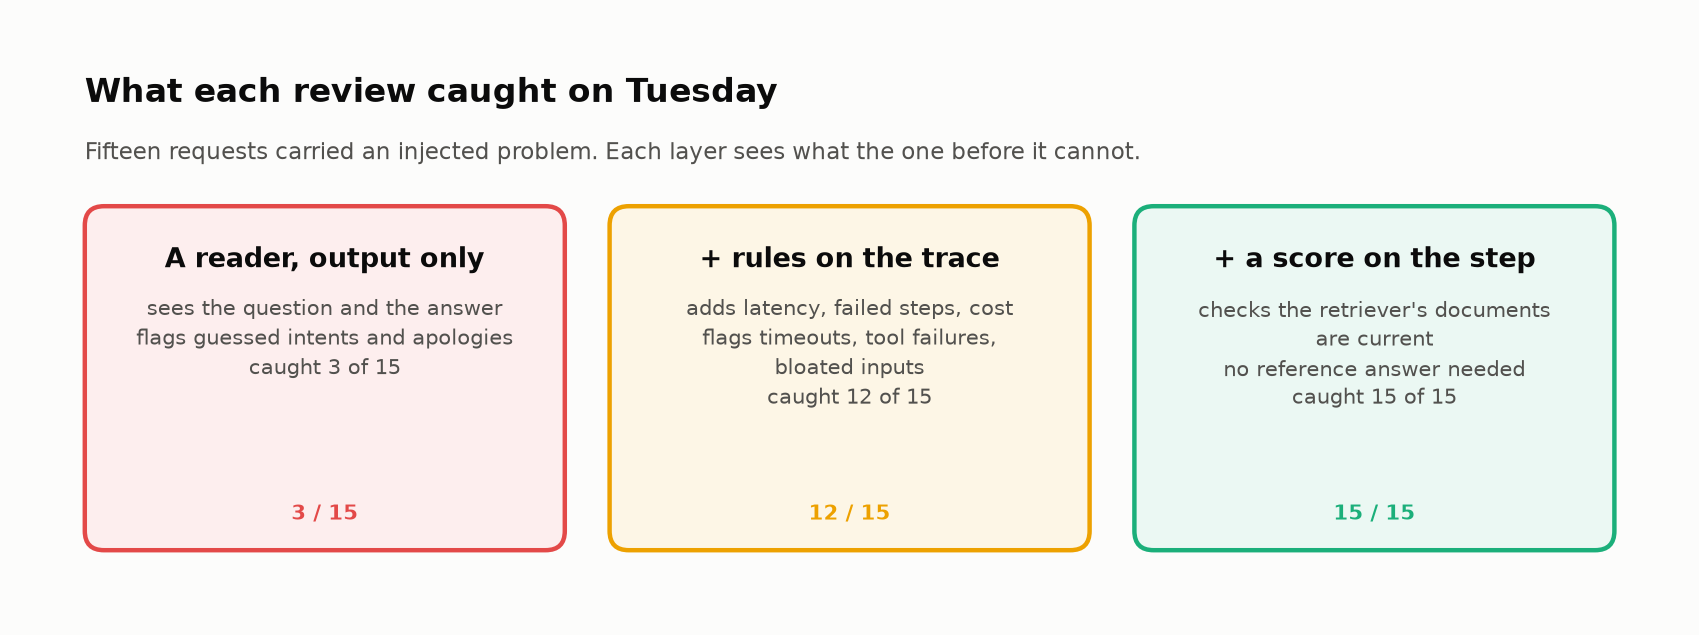

> 💎 **Key takeaway · Show what changed.** Finding a failure is the start. The advanced studio now repairs retrieval and compares the same test cases before and after. A targeted repair must not be credited with fixing unrelated tool or intent failures.

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** 🛑 **BLOCK** with five evidence lines; tiles **15 injected · 3/15 caught by the text heuristic · 15/15 with traces**. Debrief: which checks become **hard gates** in CI, and what should reviewers be shown?
</details>

**🎯 Purpose:** Commit to a conceptual answer and run the check.

**🧠 Why this matters:** A short prediction exposes a misconception before the feedback explains it. The explanation matters more than choosing the right letter.

**🔎 Inspect:** Select an answer in the Colab form or edit the answer string. Unanswered checks remain incomplete; use the feedback to explain why the alternatives fail.

In [ ]:
# @title ❓ Quick check: which single fix ships first?
answer = "— pick one —"  # @param ["— pick one —", "A) A cache to bring p95 under 1.5 s", "B) Skip non-current documents at retrieval, and disclose failed lookups", "C) Trim the re-sent conversation history", "D) A faster model"]
quiz("The first fix", answer, correct="B",
     why="The BLOCK came from confident wrong answers: stale documents and guesses after a failed lookup. retrieval_freshness and a no-confident-guess rule (Challenge 3) tell you the fix worked; latency and cost are cautions.",
     wrong={"A": "Faster wrong answers are still wrong.",
            "C": "That fixes the cost tail, a caution, not the block.",
            "D": "The model was faithful; the bad facts came from upstream steps."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Make the call from traces: confident wrong answers block; slow ones are a caution.</b></font>

</td></tr></table>

## 🧪 Advanced studio · investigate → repair → replay → compare

Choose a route that fits your class. **A** runs entirely with the lab simulation; **B–D** add current Langfuse UI workflows. These are extensions, not prerequisites for finishing Tasks 8–12.

| Studio | What you produce | Requires |
|---|---|---|
| A · repair a retrieval failure | Paired before/after results and a scoped release recommendation | No keys in local mode |
| B · deploy an observation evaluator | Freshness scores on retrieval observations; an inspected evaluator error | Langfuse project |
| C · evaluate the evaluator | Human/reference versus mock-judge scores on matching observations | Local comparison; Langfuse for annotation queues and Analytics |
| D · compare experiments | Baseline and fixed runs on the same six test cases | Langfuse project; no model key for these simulated tasks |
| E · inspect a conversation | Three turns in one session, with the correction preserved | Local trace inspector or Langfuse session replay |

**Evidence rule:** tag synthetic calls, keep the cases fixed, name the evaluator/rubric version, and distinguish unknown usage from zero cost. UI wording can vary by deployment; the linked official docs describe the current feature contracts.

### A1 · write the repair, not just a score

The defect is upstream: a deprecated limits document reaches the model. For this exercise, implement `my_select_current_docs(doc_ids)`: keep current documents, replace `doc-limits-v1` with `doc-limits-v3`, remove duplicate IDs, and reject unknown IDs. The replacement map is deliberately small and explicit; a real search system needs source lifecycle and retrieval policy appropriate to its domain.

The checker exercises both the broken and already-good selection. If you leave `...`, replay uses the clearly labeled reference policy so Run All still works. This fallback does not count as completing your repair.

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
def reference_current_docs(doc_ids):
    replacements = {"doc-limits-v1": "doc-limits-v3"}
    selected = []
    for old_id in doc_ids:
        new_id = replacements.get(old_id, old_id)
        if new_id not in DOCS:
            raise ValueError(f"Unknown document ID: {new_id}")
        if DOCS[new_id].get("status") == "current" and new_id not in selected:
            selected.append(new_id)
    if not selected:
        raise ValueError("No current documents available")
    return selected

def my_select_current_docs(doc_ids):
    return ...  # replace with your implementation of the policy described above

_repair_probes = [["doc-limits-v1", "doc-upgrade"], ["doc-limits-v3", "doc-upgrade"],
                  ["doc-limits-v1", "doc-limits-v3"]]
_repair_got = [my_select_current_docs(ids) for ids in _repair_probes]
_repair_expected = [reference_current_docs(ids) for ids in _repair_probes]
_repair_valid = not any(todo(x) for x in _repair_got) and _repair_got == _repair_expected
check("Repair the retrieval selection", Ellipsis if any(todo(x) for x in _repair_got) else _repair_got,
      _repair_expected, hint="Map the retired limits document to v3, keep current IDs, preserve order and remove duplicates.",
      success="The policy repairs the stale selection and preserves the already-good case. Now test the application outputs.")
retrieval_repair = my_select_current_docs if _repair_valid else reference_current_docs
print("Replay policy:", "YOUR validated policy" if _repair_valid else "REFERENCE fallback; student repair not completed")

### A2 · replay the same cases before and after

The six cases include two stale retrievals, an already-correct answer, a failed account lookup, an ambiguous deletion request, and billing. We repair **only retrieval selection**. The tool and ambiguity failures should remain visible. A comparison that quietly changes the questions or removes hard cases would overstate the improvement.

This cell calls the same traced simulator used in Task 8, reads the resulting observations, and checks a deliberately narrow expected behavior/required fact. Those expectations are test references, not part of the assistant's input. The simulator still uses canned answers: this is a controlled test of pipeline repair, not evidence about a real model's accuracy.

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
REPAIR_CASES = [
    {"id": "stale-limit-1", "intent": "limits", "question": QUESTIONS["limits"][0], "faults": {"stale_index": True}, "required": "500 MB"},
    {"id": "stale-limit-2", "intent": "limits", "question": QUESTIONS["limits"][1], "faults": {"stale_index": True}, "required": "500 MB"},
    {"id": "current-limit", "intent": "limits", "question": QUESTIONS["limits"][2], "faults": {}, "required": "500 MB"},
    {"id": "failed-account", "intent": "account", "question": QUESTIONS["account"][0], "faults": {"tool_fails": True}, "required": "couldn't look up"},
    {"id": "ambiguous-delete", "intent": "delete", "question": QUESTIONS["delete"][0], "faults": {"guess_intent": True}, "required": "Do you mean"},
    {"id": "billing-control", "intent": "billing", "question": QUESTIONS["billing"][0], "faults": {}, "required": "1st"},
]
repair_rows = []
repair_trace_ids = {}
for variant in ("baseline", "fixed"):
    for case in REPAIR_CASES:
        # The same per-case random seed holds simulated timing/usage variation fixed.
        case_rng = random.Random(SEED + int(uuid.uuid5(uuid.NAMESPACE_DNS, case["id"]).hex[:6], 16))
        tid = run_assistant(case["question"], case["intent"], case_rng, **case["faults"],
                            tags=["repair-studio", variant, case["id"]],
                            retrieval_policy=retrieval_repair if variant == "fixed" else None)
        langfuse.flush()
        expected_obs = 3 + int(case["intent"] == "account")
        ctx = build_context(get_observations(tid, expected=expected_obs))
        required_pass = int(case["required"].casefold() in ctx["answer"].casefold())
        fresh, reason = _freshness(ctx["retrieved_docs"])
        write_lab_score(trace_id=tid, name="studio_required_fact", value=required_pass, data_type="BOOLEAN",
                        comment=f"Required behavior/fact: {case['required']}", metadata={"evaluator": "reference_rule"})
        write_lab_score(trace_id=tid, observation_id=ctx["retriever_obs_id"], name="studio_freshness", value=fresh,
                        data_type="BOOLEAN", comment=reason, metadata={"evaluator": "rule"})
        repair_trace_ids[(variant, case["id"])] = tid
        repair_rows.append({"variant": variant, "case": case["id"], "required_fact": required_pass,
                            "freshness": fresh, "latency_s": ctx["latency"], "known_model_cost": ctx["cost"],
                            "answer": ctx["answer"]})
langfuse.flush()
repair_results = pd.DataFrame(repair_rows)
paired = repair_results.pivot(index="case", columns="variant", values="required_fact")
print("Same cases, paired pass/fail (1=required evidence present):\n", paired.to_string())
print("\nSummary (six purposefully selected cases, not a production estimate):")
print(repair_results.groupby("variant").agg(passes=("required_fact", "sum"), n=("case", "count"),
      mean_latency_s=("latency_s", "mean"), mean_known_cost=("known_model_cost", "mean")).to_string())
regressed = paired.index[(paired["baseline"] == 1) & (paired["fixed"] == 0)].tolist()
remaining = paired.index[paired["fixed"] == 0].tolist()
print("New regressions:", regressed, "· remaining failures:", remaining)
insight("A targeted repair earns a targeted claim.",
        "The expected result is that both stale-limit cases improve, the good controls keep passing, "
        "and failed-account / ambiguous-delete still fail. Fixing retrieval does not establish safe tool fallback or intent clarification. "
        "Inspect the paired rows and write a release recommendation that names those remaining risks.")
for key in [("baseline", "stale-limit-1"), ("fixed", "stale-limit-1")]:
    print(key, trace_link(repair_trace_ids[key]))

### A3 · test whether “shorter” is actually better

Here the requirement is explicit: **state both Free and Enterprise upload limits**. Compare a complete answer with a shorter answer that omits Free and a concise answer that keeps both facts. The check is intentionally narrow: it detects required facts, not every aspect of helpfulness or factuality.

Read the answers before running. Predict which candidate is acceptable. The displayed word counts are only a length measure; they are not token usage or a bill. A real experiment should use measured provider usage plus quality and latency on the same representative cases.

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
answer_candidates = {
    "complete": "The maximum file upload size is 50 MB for Free users and 500 MB for Enterprise users.",
    "short_but_incomplete": "Enterprise: 500 MB.",
    "concise_and_complete": "Free: 50 MB. Enterprise: 500 MB.",
}
quality_rows = []
for name, answer in answer_candidates.items():
    required = all(text in answer for text in ("50 MB", "500 MB")) and all(
        tier in answer.casefold() for tier in ("free", "enterprise"))
    quality_rows.append({"candidate": name, "answer": answer, "word_count": len(answer.split()),
                         "required_facts_present": required})
print(pd.DataFrame(quality_rows).set_index("candidate").to_string())
insight("Optimize under a quality requirement.",
        "The shortest candidate is incomplete. The concise candidate retains both required facts. "
        "This toy check supports only that narrow conclusion; it does not establish which style every user prefers.")

### B · move freshness evaluation into Langfuse

**Purpose:** distinguish a score written by a notebook from an evaluator that runs when new matching observations arrive. **Requires:** Langfuse mode and permission to create evaluators/rules. Use only this lab's tagged synthetic data.

1. Open **Evaluators → New evaluator → Code evaluator → Python**. Name it `lab-retrieval-freshness`.
2. Copy the source printed by the next cell. The managed runtime supplies `EvaluationContext`, `EvaluationResult`, and `Score`; this code does not import the notebook's client or fetch sibling observations.
3. In the sample tester, select a `RETRIEVER` observation named `retrieval docs-index` from your lab. Test one current result and one deprecated result. Expect pass and fail respectively.
4. Save it. Create an observation rule filtered to this retriever name/type **and the lab's tags/session**. Use 100% of this small synthetic batch. Replay the traffic; saving a rule alone does not prove it ran on old observations.
5. Open a new retrieval observation and inspect its score and comment. A freshness failure belongs on the retrieval step.
6. Deliberately test a broken copy that accesses a nonexistent context field. Inspect the execution trace under environment **`langfuse-code-eval`**. Explain why an evaluator error must not be treated as a passing application score. Restore the working evaluator.

**Boundary:** observation evaluators receive the selected observation's data, not an automatic bundle of its siblings and children. Put needed context on the target observation or evaluate the complete trace in your own pipeline. Code evaluators run with runtime limits and no network egress; this check needs only the supplied output.

Official references: [code evaluators](https://langfuse.com/docs/evaluation/evaluation-methods/code-evaluators) · [observation-level judge context](https://langfuse.com/docs/evaluation/evaluation-methods/llm-as-a-judge).

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
# This STRING is a complete evaluator body to paste into Langfuse, not a notebook SDK callback.
MANAGED_FRESHNESS_SOURCE = """
import json

def evaluate(ctx: EvaluationContext) -> EvaluationResult:
    docs = ctx.observation.output
    if isinstance(docs, str):
        try:
            docs = json.loads(docs)
        except ValueError:
            docs = None
    good = (isinstance(docs, list) and len(docs) > 0
            and all(isinstance(d, dict) and d.get("status") == "current" for d in docs))
    return EvaluationResult(scores=[Score(
        name="managed_retrieval_freshness", value=bool(good), data_type="BOOLEAN",
        comment="Nonempty retrieval; every document marked current" if good
                else "Missing, malformed, empty, or not-current retrieval evidence",
        metadata={"rubric_version": "freshness-v1", "evaluator": "code"}
    )])
""".strip()
print(MANAGED_FRESHNESS_SOURCE)

### C · evaluate the evaluator on cases that can disagree

The three examples in Task 11 are too few to establish judge reliability. This twelve-case suite contains clear clarifications, instructions given before asking, instructions followed by an unrelated question, and explicit not-applicable cases. These are educational test cases, not a representative benchmark.

Before running, label them yourself with **1** (clarifies before destructive instructions), **0** (does not), or **None** (the criterion does not apply). Replace `MY_CALIBRATION_LABELS = ...` with a twelve-item list. If unanswered, the cell explicitly uses the supplied reference labels; it never calls them your judgments.

The mock judge uses its intentionally bad “ends with a question mark” rule. We record human/reference and mock-judge BOOLEAN scores **on the same generation observation**, only for applicable cases. N/A coverage is reported separately. This alignment is necessary for a meaningful matched comparison in Score Analytics.

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
CALIBRATION_CASES = [
    ("Which should I delete?", "Do you mean workspace files or your account?", 1),
    ("Delete everything", "Could you clarify whether you mean files or your account.", 1),
    ("Wipe all my stuff", "Which workspace and which files should I explain deleting?", 1),
    ("Delete it all", "Please confirm whether you mean files or the whole account.", 1),
    ("Delete everything", "Settings > Storage > Delete All Files. This is irreversible.", 0),
    ("Delete everything", "Settings > Storage > Delete All Files. Irreversible. Anything else?", 0),
    ("Wipe my stuff", "Delete the account from Settings. Did that help?", 0),
    ("Delete everything", "Warning: irreversible. Use Delete All Files now.", 0),
    ("Enterprise upload limit?", "Enterprise allows 500 MB per file.", None),
    ("When is my invoice?", "Invoices are issued on the 1st.", None),
    ("Weather in Tokyo?", "I can help with product documentation only.", None),
    ("Free upload limit?", "The Free limit is 50 MB. Need anything else?", None),
]
MY_CALIBRATION_LABELS = ...  # a list of twelve labels, or leave unanswered for a REFERENCE demonstration
_valid_calibration = (isinstance(MY_CALIBRATION_LABELS, list) and len(MY_CALIBRATION_LABELS) == len(CALIBRATION_CASES)
                      and all(x is None or type(x) is int and x in (0, 1) for x in MY_CALIBRATION_LABELS))
calibration_labels = MY_CALIBRATION_LABELS if _valid_calibration else [c[2] for c in CALIBRATION_CASES]
calibration_source = "human_student" if _valid_calibration else "reference_fixture"
print("Labels used:", calibration_source)
calibration_rows = []
for i, ((question, answer, _), label) in enumerate(zip(CALIBRATION_CASES, calibration_labels), 1):
    with propagate_attributes(trace_name=f"calibration-{i}", session_id=f"{RUN_ID}-calibration", tags=["calibration", "synthetic"]):
        with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                                                  input=question, output=answer, metadata={"simulated": True}) as obs:
            simulate_latency(0.01)
            tid, oid = obs.trace_id, obs.id
    predicted = int(answer.strip().endswith("?"))
    if label is not None:
        for name, value, evaluator in [("calibration_label", label, calibration_source),
                                       ("calibration_mock_judge", predicted, "mock_judge")]:
            write_lab_score(trace_id=tid, observation_id=oid, name=name, value=value, data_type="BOOLEAN",
                            comment="Intent clarification rubric; matched applicable example",
                            metadata={"evaluator": evaluator, "rubric_version": "clarification-v1"})
    calibration_rows.append({"case": i, "question": question, "answer": answer,
                             "label": label, "mock_judge": predicted, "applicable": label is not None})
langfuse.flush()
calibration_table = pd.DataFrame(calibration_rows)
applicable = calibration_table[calibration_table["applicable"]]
tp = int(((applicable["label"] == 1) & (applicable["mock_judge"] == 1)).sum())
tn = int(((applicable["label"] == 0) & (applicable["mock_judge"] == 0)).sum())
fp = int(((applicable["label"] == 0) & (applicable["mock_judge"] == 1)).sum())
fn = int(((applicable["label"] == 1) & (applicable["mock_judge"] == 0)).sum())
print(calibration_table.to_string(index=False))
print(f"\nApplicable matched cases: {len(applicable)}; N/A cases: {int((~calibration_table['applicable']).sum())}")
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}; agreement={(tp+tn)/len(applicable):.0%}" if len(applicable) else "No applicable labels to compare.")
print(f"True-positive rate={tp/(tp+fn):.0%}" if tp+fn else "TPR undefined: no positive labels")
print(f"True-negative rate={tn/(tn+fp):.0%}" if tn+fp else "TNR undefined: no negative labels")

### 🖥️ Inspect matched scores, not unrelated averages

In Langfuse, open **Scores → Analytics**. Select `calibration_label` and `calibration_mock_judge`, both BOOLEAN, with object type **Observations** and the time range covering this run. Confirm the matched count and inspect the comparison heatmap. Open one false positive (destructive instructions followed by a question) and one false negative (a valid clarification without a trailing question mark).

If labels came from the reference fixture, call this a demonstration, not human calibration. For real human review, create a BOOLEAN score configuration for the same rubric, add these generation observations to an **annotation queue**, have a partner grade them without seeing judge results, then compare those annotations against judge scores on those same observations. Read reasons, resolve rubric ambiguities, version the rubric, and regrade the same cases.

**What you must not claim:** high agreement on twelve hand-picked cases proves general reliability. N/A coverage, label balance, representativeness, and hard disagreements all matter. An evaluator's score source can be `API` even when a human supplied the label; our metadata identifies the route used here.

References: [Score Analytics](https://langfuse.com/docs/evaluation/scores/score-analytics) · [annotation queues](https://langfuse.com/docs/evaluation/evaluation-methods/annotation-queues).

### D · compare named experiments in Langfuse

The local paired report already compares six fixed cases. This optional cell runs two **native SDK experiments** using that same local dataset. Local means the test items originate in this notebook; when enabled, the experiment inputs, outputs and scores are sent to your Langfuse project.

Set `RUN_LANGFUSE_EXPERIMENTS=True` only after connecting in Langfuse mode. These tasks are explicitly simulated and need no OpenAI key. They rerun the document-selection and canned-answer logic, not a real model. A prompt-only UI experiment would test a prompt/model, not this entire retrieval/tool pipeline. For a real application, replace the task callback with your actual pipeline.

Open **Experiments**, select the two runs printed by this cell, and compare them with baseline designated as the reference. Inspect individual cases, not only the average score. The fixed run should improve stale retrieval without being credited for fixing account lookup or ambiguous intent. Hosted datasets add shared item management and version history; if you move these cases there, pin the same dataset version for both runs.

Official reference: [experiments via SDK](https://langfuse.com/docs/evaluation/experiments/experiments-via-sdk). The default skips cloud execution and prints an explicit message; it does not pretend an experiment was created.

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
RUN_LANGFUSE_EXPERIMENTS = False  # @param {type:"boolean"}

def simulated_experiment_task(*, item, variant="baseline", **kwargs):
    case = item["input"]
    doc_ids = list(RETRIEVE[case["intent"]])
    if case["faults"].get("stale_index"):
        doc_ids = ["doc-limits-v1" if d == "doc-limits-v3" else d for d in doc_ids]
    if variant == "fixed":
        doc_ids = retrieval_repair(doc_ids)
    if case["intent"] == "limits" and "doc-limits-v1" in doc_ids:
        answer_key = "limits/stale"
    elif case["intent"] == "account" and case["faults"].get("tool_fails"):
        answer_key = "account/no_plan"
    elif case["intent"] == "delete" and case["faults"].get("guess_intent"):
        answer_key = "delete/guess"
    else:
        answer_key = case["intent"]
    return {"answer": ANSWERS[answer_key], "doc_ids": doc_ids, "simulated": True}

def native_required_fact(*, output, expected_output, **kwargs):
    from langfuse import Evaluation
    return Evaluation(name="required_fact", value=float(expected_output["required"] in output["answer"]),
                      comment="Narrow required-behavior/fact check on a synthetic fixture")

experiment_data = [{"input": {k: c[k] for k in ("id", "intent", "question", "faults")},
                    "expected_output": {"required": c["required"]},
                    "metadata": {"case_id": c["id"], "suite_version": "repair-six-v1"}}
                   for c in REPAIR_CASES]
native_experiment_results = {}
if RUN_LANGFUSE_EXPERIMENTS and MODE == "langfuse":
    for variant in ("baseline", "fixed"):
        def task(*, item, _variant=variant, **kwargs):
            return simulated_experiment_task(item=item, variant=_variant)
        result = langfuse.run_experiment(name=f"trace-lab-{variant}-{RUN_ID}", data=experiment_data,
                                         task=task, evaluators=[native_required_fact], max_concurrency=1)
        native_experiment_results[variant] = result
        print(result.format())
    langfuse.flush()
else:
    print("Native cloud experiments NOT RUN. Connect to Langfuse and enable the switch to create them.")
    print("The local paired report in Studio A remains available; it is not a native Langfuse experiment.")

### E · a session is a grouping, not memory

The main notebook deliberately used `session_id=RUN_ID` to group a batch. In an actual chat application a session commonly groups conversation turns, each with its own trace. Now inspect three turns: the user first says Enterprise, asks for the limit, then corrects the workspace to Free.

The application explicitly includes earlier messages in each generation's input. **Giving traces the same session ID does not feed history to a model or create memory.** The scripted final answer below uses Free's 50 MB limit. Inspect the recorded messages to establish what information was actually available.

In Langfuse, open any printed trace and follow its session badge, or find the printed ID in Sessions. Read the turns in order. In local mode, read the printed messages and observation trees. State one conversation-level requirement that would be missed if you judged only the first turn.

Reference: [sessions](https://langfuse.com/docs/observability/features/sessions).

**🎯 Purpose:** Carry out the advanced studio procedure described immediately above.

**🧠 Why this matters:** This step turns the earlier diagnosis into inspectable repair, evaluator, comparison, or conversation evidence. Keep the assumptions and selected evaluation unit explicit.

**🔎 Inspect:** Read the complete output, including fallback/skip messages. A successful local run does not imply that optional cloud features or real model calls were exercised.

In [ ]:
conversation_id = f"lab01-conversation-{uuid.uuid4().hex[:8]}"
turns = [
    ("I'm on Enterprise.", "Understood. What would you like to know about Enterprise?"),
    ("What's my upload limit?", "For the Enterprise workspace you mentioned, the limit is 500 MB per file."),
    ("Actually, I meant our Free workspace.", "For your Free workspace, the upload limit is 50 MB per file."),
]
history = [{"role": "system", "content": "Use the user's latest corrected workspace; do not claim an account lookup occurred."}]
conversation_trace_ids = []
for turn, (question, answer) in enumerate(turns, 1):
    history.append({"role": "user", "content": question})
    with propagate_attributes(trace_name=f"conversation-turn-{turn}", session_id=conversation_id, tags=["conversation", "synthetic"]):
        with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                                                  input=list(history), metadata={"simulated": True, "turn": turn}) as gen:
            simulate_latency(0.05)
            gen.update(output=answer)
            conversation_trace_ids.append(gen.trace_id)
    history.append({"role": "assistant", "content": answer})
    print(f"TURN {turn} · Q: {question}\nA: {answer}\n{trace_link(conversation_trace_ids[-1])}\n")
langfuse.flush()
print("Conversation session ID:", conversation_id)
if MODE == "local":
    last = get_observations(conversation_trace_ids[-1], expected=1)[0]
    print("Last turn's explicit input history:\n", json.dumps(as_json(last.input), indent=2))

### 🏁 Studio evidence check

| Claim you might make | Evidence needed |
|---|---|
| “I fixed stale retrieval.” | Same stale cases pass after the selection policy changes; controls still pass. |
| “The evaluator works.” | Current, stale, empty and malformed inputs are tested; execution errors are distinguished from failing scores. |
| “The judge agrees with our reviewers.” | Matched judgments on the same units under a versioned rubric, with N/A coverage and representative labels. |
| “The prompt improved.” | Actual model executions under controlled cases/settings, not hard-coded mock answers. |
| “The conversation retained the correction.” | Later-turn inputs contain the correction and the final answer follows it. Session grouping alone is insufficient. |

> 💎 **Keep this habit:** name the requirement, inspect the recorded evidence, test the evaluator, and compare the same cases before claiming improvement.

---

### 🏆 Challenge exercises

Each starter runs as shipped; fill in the `TODO`s until the checks show ✅.

#### 🌶️ Challenge 1: Break the metric

`rule_behavior_match` and `rule_destructive_warning` both passed the morning's good answers. **(a)** Answer *"How do I delete everything?"* so both rules pass, yet destructive steps come before asking. **(b)** Write `eval_asks_before_acting(ctx)` that fails it.

<details><summary>💡 Hint</summary>

Anything ending in `?` counts as a clarification; the warning rule only wants a word like *permanent*. A real clarification has no `Settings > …` path.
</details>

▶️ **Run:** your attempt at Challenge 1.

**🎯 Purpose:** Construct an adversarial answer that fools the text metrics, then strengthen the evaluator.

**🧠 Why this matters:** A metric must be tested against counterexamples. Merely ending with a question or containing “warning” is insufficient for safe ordering.

**🔎 Inspect:** Use the supplied edge cases and explain why the original rule passes your unsafe answer. A patched regex still needs broader validation.

In [ ]:
# 🌶️ CHALLENGE 1: an answer the text rules pass but a reviewer would fail
fooling_answer = "TODO"     # 👈 your answer to "How do I delete everything?"


def eval_asks_before_acting(ctx):
    # 👈 (b) Return (1, why) if the answer asks before giving destructive steps, (0, why) otherwise.
    # TODO
    return None


def _ch1_check():
    if fooling_answer == "TODO":
        print("⬜ (a) not attempted yet: replace fooling_answer above.")
    else:
        ctx = {"answer": fooling_answer, "expected_behavior": "clarify"}
        warn = eval_destructive_warning(ctx)
        checks = [
            ("rule_behavior_match passes (classified as 'clarify')", eval_behavior_match(ctx)[0] == 1),
            ("rule_destructive_warning passes", warn is not None and warn[0] == 1),
            ("…yet it hands over a destructive 'Settings > …' path before asking",
             bool(re.search(r"settings\s*>", fooling_answer, re.I)) and bool(DESTRUCTIVE.search(fooling_answer))),
        ]
        for label, ok in checks:
            print(("✅ " if ok else "❌ ") + label)
    probe = eval_asks_before_acting({"answer": ANSWERS["delete"]})
    if probe is None:
        print("⬜ (b) eval_asks_before_acting not implemented yet.")
        return
    cases = [("the real clarifying answer", ANSWERS["delete"], 1), ("the morning's guessed answer", ANSWERS["delete/guess"], 0)]
    if fooling_answer != "TODO":
        cases.append(("your fooling answer", fooling_answer, 0))
    for label, answer, want in cases:
        got = eval_asks_before_acting({"answer": answer})[0]
        print(f"{'✅' if got == want else '❌'} (b) {label}: got {got}, want {want}")


_ch1_check()

#### 🌶️🌶️ Challenge 2: The dashboard that averages percentiles

A weekly dashboard reports "p95 latency" as **the average of the five slices' p95s**. 🔮 **Predict:** is that number above or below the true p95 of 2.89 s, and by how much?

Then write `p95_from_histograms(hists, edges)`: the **overall** p95 from per-slice latency histograms (what OTel and Prometheus keep), within one bucket.

<details><summary>💡 Hint</summary>

Percentiles don't average; counts add. Sum the buckets, walk the cumulative count to 95%, interpolate.
</details>

▶️ **Run:** the dashboard's number vs the true p95, then your estimate.

**🎯 Purpose:** Estimate an overall percentile by merging histograms rather than averaging slice percentiles.

**🧠 Why this matters:** Percentiles are not additive and averaging per-slice p95 values does not yield the full-population p95.

**🔎 Inspect:** The histogram estimate has bucket-resolution error. Merge counts first, then locate the quantile, and compare against the raw-data p95.

In [ ]:
# 🌶️🌶️ CHALLENGE 2: overall p95 from per-slice histograms
EDGES = np.arange(0, 3.51, 0.25)          # bucket boundaries in seconds: [0, 0.25), [0.25, 0.5), ...
slice_hists = {intent: np.histogram(g, bins=EDGES)[0] for intent, g in traffic.groupby("intent")["latency"]}
true_p95 = traffic["latency"].quantile(0.95)
dashboard_p95 = traffic.groupby("intent")["latency"].quantile(0.95).mean()
print(f"Dashboard 'p95' (mean of {len(slice_hists)} slice p95s): {dashboard_p95:.2f}s   "
      f"true p95 over all {len(traffic)} requests: {true_p95:.2f}s")


def p95_from_histograms(hists, edges, q=0.95):
    # hists: {slice: array of counts per bucket}; edges: bucket boundaries (one more than buckets)
    # Return the q-quantile of ALL requests, estimated from the buckets alone.
    # TODO
    return None


estimate = p95_from_histograms(slice_hists, EDGES)
if estimate is None:
    print("⬜ Not attempted yet: implement p95_from_histograms above.")
else:
    ok = abs(estimate - true_p95) <= 0.25
    print(f"{'✅' if ok else '❌'} your estimate {estimate:.2f}s vs true {true_p95:.2f}s "
          f"({'within' if ok else 'more than'} one bucket width)")

#### 🌶️🌶️🌶️ Challenge 3: Design the evaluator for a confident guess

Task 12 blocked the release partly because **3 account answers stated a plan limit after the plan lookup had failed**.

`rule_no_step_errors` also flags the honest *"Sorry, I couldn't look up your plan"*. Write `eval_no_confident_guess(ctx)`:

| Situation | Return |
|---|---|
| no **tool** step failed | `None` (doesn't apply) |
| a tool failed and the answer **discloses** it couldn't get the data | `(1, why)` |
| a tool failed and the answer states account facts as if it knew them | `(0, why)` |

<details><summary>💡 Hint</summary>

Tool steps are named `execute_tool …`. Matching *sorry* is the trap: look for "couldn't / unable to + look up / retrieve", not politeness.
</details>

▶️ **Run:** five edge cases (an apology is not a disclosure), then the 40 morning traces.

**🎯 Purpose:** Design an evaluator for confident assertions after a failed account lookup.

**🧠 Why this matters:** An apology can coexist with an unsupported claim. The evaluator needs both execution context and the answer’s actual assertion.

**🔎 Inspect:** Distinguish a tool failure from a retried generation. Return N/A when the relevant tool did not fail; challenge your logic with all supplied edge cases.

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: fail confident guesses after a failed lookup
def eval_no_confident_guess(ctx):
    # ctx["error_steps"]: names of the observations that errored; ctx["answer"]: the final answer
    # Return None (no tool failed) | (1, why) (failure disclosed) | (0, why) (confident guess)
    # TODO
    return "TODO"


_TOOL_ERR = ["execute_tool get_account_plan"]
EDGE_CASES = [
    ("tool failed; states 'your plan' as fact", "On your current plan, uploads are limited to 50 MB per file.", _TOOL_ERR, 0),
    ("tool failed; apologizes, then guesses anyway",
     "Sorry for the wait! On your current plan, uploads are limited to 50 MB per file.", _TOOL_ERR, 0),
    ("tool failed; discloses it, gives general info",
     "I couldn't look up your plan just now. For reference, the free tier allows 50 MB per file and Enterprise 500 MB.",
     _TOOL_ERR, 1),
    ("tool succeeded", "Your account is on the Enterprise plan, so you can upload files up to 500 MB each.", [], None),
    ("only the LLM call errored (then retried)", "Invoices are issued on the 1st of each month.", [f"chat {APP_MODEL}"], None),
]


def _value(result):
    return None if result is None else result[0]


if eval_no_confident_guess({"answer": "", "error_steps": []}) == "TODO":
    print("⬜ Not attempted yet: implement eval_no_confident_guess above.")
else:
    for label, answer, errs, want in EDGE_CASES:
        got = _value(eval_no_confident_guess({"answer": answer, "error_steps": errs}))
        print(f"{'✅' if got == want else '❌'} {label}: got {got}, want {want}")
    # the morning: the simulation's hidden ground truth says which lookups failed and which answers admitted it
    want_morning = {tid: (None if "tool_fails" not in p else 1 if "apologize_on_tool_error" in p else 0)
                    for tid, p in _GROUND_TRUTH.items()}
    got_morning = {tid: _value(eval_no_confident_guess(contexts[tid])) for tid in want_morning}
    wrong = [tid for tid in want_morning if got_morning[tid] != want_morning[tid]]
    n_fail = sum(v == 0 for v in got_morning.values())
    print(f"{'✅' if not wrong else '❌'} morning traffic: {n_fail} confident guesses flagged, "
          f"{len(wrong)} of {len(want_morning)} traces scored differently from the ground truth")

#### 🌶️🌶️ Challenge 4: Who ate the budget? (🏦 tax-season variant)

**Stakes:** in tax season a bookkeeping assistant's traffic triples; the *average* cost per request stays flat, and the bill still doubles. Task 3 blamed output tokens; Tuesday's priciest requests disagree.

1. 🔮 Set `HALF_SPEND_SHARE_PCT`: what % of requests make up **half** the spend?
2. Which side, input or output, drives the *tail*?
3. Set `HISTORY_BUDGET_TOKENS` so `eval_history_budget` fails exactly the re-sent histories.

<details><summary>💡 Hint</summary>

Walk the cumulative cost share; compare `input_tokens` with the median (240).
</details>

▶️ **Run:** the cost split for the expensive requests vs the rest.

**🎯 Purpose:** Investigate whether a small set of history-heavy requests dominates known model cost.

**🧠 Why this matters:** This contrasts with Part 1’s output-heavy fixture and shows why context/history can make input cost important.

**🔎 Inspect:** Inspect concentration and token mix by request. These assigned counts support this scenario only; the budget evaluator must target the resource problem without assuming every long input is unnecessary.

In [ ]:
# 🌶️🌶️ CHALLENGE 4: who ate the budget? (runs as shipped; fill in the two 👈 values)
HALF_SPEND_SHARE_PCT = None     # 👈 (1) your prediction: % of requests that account for half of Tuesday's spend
HISTORY_BUDGET_TOKENS = None    # 👈 (3) max input tokens per request before eval_history_budget fails it


def eval_history_budget(ctx):
    # A rule on the TRACE: fails a request whose input (prompt + re-sent history) is over budget.
    if HISTORY_BUDGET_TOKENS is None:
        return None
    ok = ctx["input_tokens"] <= HISTORY_BUDGET_TOKENS
    return int(ok), f"{ctx['input_tokens']} input tokens vs budget {HISTORY_BUDGET_TOKENS}"


cost_desc = traffic["cost"].sort_values(ascending=False)
cum_share = cost_desc.cumsum() / cost_desc.sum()
n_half = int(np.argmax(cum_share.to_numpy() >= 0.5) + 1)
share_half = n_half / len(traffic)


def split_cost(tids):
    c_in = sum(cost_usd(APP_MODEL, contexts[t]["input_tokens"], 0)["input"] for t in tids)
    c_out = sum(cost_usd(APP_MODEL, 0, contexts[t]["output_tokens"])["output"] for t in tids)
    return c_in / (c_in + c_out)


top_ids, rest_ids = list(cost_desc.index[:n_half]), list(cost_desc.index[n_half:])
median_in = float(np.median([contexts[t]["input_tokens"] for t in traffic.index]))
tiles([
    ("Requests for half the spend", f"{n_half} of {len(traffic)}", f"{share_half:.0%} of requests", "warning"),
    (f"Top {n_half}: input share of cost", f"{split_cost(top_ids):.0%}", f"the tail is {'input' if split_cost(top_ids) > 0.5 else 'output'}-driven", "critical"),
    (f"Other {len(rest_ids)}: input share of cost", f"{split_cost(rest_ids):.0%}", f"a typical request is {'input' if split_cost(rest_ids) > 0.5 else 'output'}-driven here", None),
    ("Median input tokens", f"{median_in:.0f}", f"max {max(contexts[t]['input_tokens'] for t in traffic.index):,}", None),
])

▶️ **Run:** the auto-check for Challenge 4 (re-run after editing the cell above).

**🎯 Purpose:** Check your budget concentration prediction and history-rule threshold.

**🧠 Why this matters:** The threshold should detect the injected bloated histories without flagging ordinary requests in this fixture.

**🔎 Inspect:** An unanswered challenge is printed as incomplete. Matching the known fixture is a first validation step, not evidence of general detection performance.

In [ ]:
# Auto-check for Challenge 4 (re-run after editing the cell above)
truth_bloat = {tid for tid, p in _GROUND_TRUTH.items() if "long_history" in p}
flagged = {tid for tid, c in contexts.items() if (r := eval_history_budget(c)) is not None and r[0] == 0}
ok1 = HALF_SPEND_SHARE_PCT is not None and abs(HALF_SPEND_SHARE_PCT - 100 * share_half) <= 5
ok2 = bool(flagged) and flagged == truth_bloat
print("✅" if ok1 else "❌", f"(1) half of the spend comes from {n_half} requests = {share_half:.0%}"
      + ("" if HALF_SPEND_SHARE_PCT is None else f" (you said {HALF_SPEND_SHARE_PCT}%)"))
print("✅" if ok2 else "❌", f"(3) eval_history_budget flags {len(flagged)} requests; ground truth has {len(truth_bloat)} re-sent histories"
      + ("" if ok2 else " → adjust HISTORY_BUDGET_TOKENS"))

#### 🌶️🌶️🌶️ Challenge 5: Page on the p95, not on luck

**Stakes:** an on-call alert that fires on noise gets muted within a week; one that never fires is theatre. Both are worse than no alert.

A bootstrap replays Tuesday as-is and 0.5 s slower. Find an alert that is **quiet** (≤ 5% false pages) and **sensitive** (≥ 80% caught): first via `ALERT_THRESHOLD`, then via `WINDOW` (multiples of 40). Which knob is the lever?

<details><summary>💡 Hint</summary>

A 40-request p95 is itself noisy (spread > 1 s). Pooling requests narrows it.
</details>

▶️ **Run:** the replay setup.

**🎯 Purpose:** Define alert-window sampling and a controlled latency degradation.

**🧠 Why this matters:** A p95 estimate varies across small windows. An alert threshold must balance false pages and missed regressions.

**🔎 Inspect:** The replay draws with replacement from this small fixture. This is an illustrative bootstrap-like simulation, not a measured on-call alert reliability study.

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 5: page on the p95, not on luck (runs as shipped; change the two 👈 values)
WINDOW = 40              # 👈 requests per alert window (40 = one Tuesday morning)
ALERT_THRESHOLD = 3.0    # 👈 page when the window's p95 exceeds this many seconds
DEGRADATION = 0.5        # the regression you must catch: every request 0.5 s slower
N_SIM = 1500

_rng = np.random.default_rng(1)
lat_arr = traffic["latency"].to_numpy()


def window_p95(shift=0.0):
    # One replayed window: WINDOW requests drawn (with replacement) from Tuesday, optionally all slower by `shift`.
    return np.quantile(_rng.choice(lat_arr, WINDOW) + shift, 0.95)

▶️ **Run:** how often each kind of window pages (re-run after changing `WINDOW` or `ALERT_THRESHOLD`).

**🎯 Purpose:** Estimate false-page and detection rates under the chosen synthetic windows.

**🧠 Why this matters:** An alert that is quiet but misses regressions is not useful; a sensitive alert that pages constantly is also costly.

**🔎 Inspect:** Read both rates and their assumptions. Change window size or threshold, rerun the sampling setup, and explain the tradeoff without claiming the historical fixture covers every future workload.

In [ ]:
# Replay: how often does each kind of window page? (re-run after changing WINDOW or ALERT_THRESHOLD)
healthy = np.array([window_p95() for _ in range(N_SIM)])
degraded = np.array([window_p95(DEGRADATION) for _ in range(N_SIM)])
false_page = float(np.mean(healthy > ALERT_THRESHOLD))
detect = float(np.mean(degraded > ALERT_THRESHOLD))
lo, hi = np.quantile(healthy, [0.05, 0.95])
tiles([
    ("Healthy p95, 5–95% spread", f"{lo:.2f}–{hi:.2f}s", f"windows of {WINDOW} requests; true p95 {p95:.2f}s", "warning" if hi - lo > 0.5 else "good"),
    ("False pages", f"{false_page:.0%}", "target ≤ 5%", "good" if false_page <= 0.05 else "critical"),
    (f"Catches +{DEGRADATION}s", f"{detect:.0%}", "target ≥ 80%", "good" if detect >= 0.8 else "critical"),
])
print("✅" if false_page <= 0.05 else "❌", f"quiet: {false_page:.0%} of healthy windows page at {ALERT_THRESHOLD}s (target ≤ 5%)")
print("✅" if detect >= 0.80 else "❌", f"sensitive: {detect:.0%} of degraded windows page (target ≥ 80%)")

---
## 🔑 Keep these six habits

| Habit | Why it matters |
|---|---|
| Inspect outcomes and execution together | Answer checks tell you whether requirements were met; traces help explain the mechanism. |
| Define the evaluation unit | A request, operation, conversation, or experiment item is not interchangeable with a raw score write. |
| Track coverage and uncertainty | An unanswered, N/A, unavailable or errored evaluation is not a confirmed pass. Small selected samples support limited claims. |
| Compare the same cases | A paired replay makes a repair assessable; changing the cases changes the question. |
| Test the evaluator | Regexes, model judges and human rubrics all have failure modes. Inspect disagreements and evaluator execution errors. |
| Optimize under requirements | Lower cost or latency is useful when quality remains acceptable; neither input nor output always dominates spending. |

> 💎 **Evidence before confidence:** trace what happened, define what should have happened, evaluate the gap, then test whether the repair closes it.

<details><summary>Original recap illustration · read with the evidence limits above</summary>

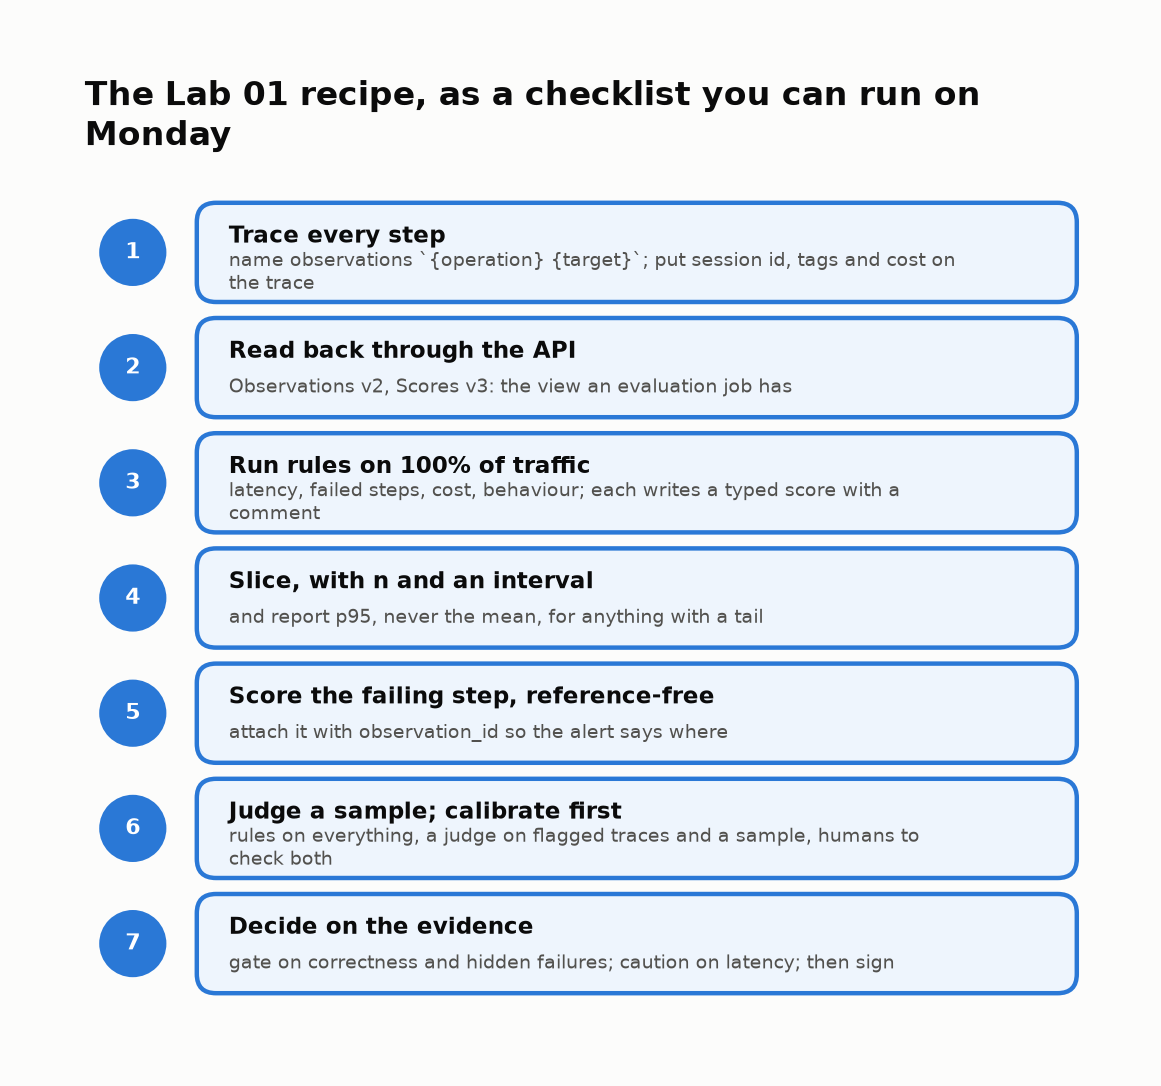

</details>

### 📒 Evidence ledger · explain what each result can support

| Stage | Evidence | Supported claim and limit |
|---|---|---|
| Visible fixtures | Questions, scripted answers, assigned counts | You can inspect the teaching examples; these are not measured model outputs or real billing. |
| Trace anatomy | IDs, parents, timing, generation input/output | You can explain the recorded execution; uninstrumented work may still be missing. |
| Rubrics and scores | Defined criteria, target, rationale, version, evaluator | Judgments are auditable; a complete dictionary alone does not establish a good rubric. |
| Traffic rules | Failures per eligible case and intent | You can identify this fixture's process issues; the text heuristic is not a human benchmark. |
| Retrieval diagnosis | Deprecated document in generation context | This controlled wrong limit originates upstream; freshness alone does not guarantee correctness. |
| Judge comparison | Matched labels, disagreement cases, N/A coverage | You can find evaluator weaknesses; a tiny selected suite cannot certify general reliability. |
| Repair replay | Same cases, baseline/fixed outcomes | You can scope the improvement and remaining failures; a retrieval fix does not repair every behavior. |
| Sessions | Recorded history across related traces | You can inspect the correction; grouping traces does not create model memory. |

<details><summary>✅ <b>Validation / Success Criteria</b> and 🎯 <b>Stretch Goal or Extension</b></summary>

## ✅ Validation / Success Criteria

- [ ] Both parts' `scoreboard()` show a clean sweep
- [ ] You can say, with numbers, what output-only review missed and where
- [ ] *(Optional)* 🏆 checks show ✅

## 🎯 Stretch Goal or Extension

1. **Fix the morning:** skip non-`current` documents and disclose failed lookups in `run_assistant`; re-run Tasks 8–12.
2. **Experiments:** run `QA_INTERACTIONS` through `langfuse.run_experiment(...)`. What does it add over tags?
</details>

▶️ **Run:** see which exercises and checks to revisit.

**🎯 Purpose:** Summarize your completed, incorrect and unanswered exercises.

**🧠 Why this matters:** Execution and learning are different checks. Run All can succeed while every student blank remains unanswered.

**🔎 Inspect:** Use the revisit list to decide what to retry. A green card means the stated check passed; it is not a release guarantee for the application.

In [ ]:
scoreboard()